# Coral NLR and microbiome analysis

Prepare and clean source data, identify NLR architecture candidates, and test their species-level associations with tissue microbiomes under frozen protocol v1.0. Run all cells in order using **Python (bio495)**. Derived outputs are regenerated; raw inputs are preserved.

Primary inference uses **8 species and 25 samples**. Neither primary test supports the predicted positive association; this does not establish absence of a biological relationship.

## Contents

1. [Environment and frozen plan](#setup)
2. [Metadata cleaning and species reconciliation](#metadata)
3. [Genome quality and reference resources](#genomes)
4. [Microbiome data preparation and preprocessing](#counts)
5. [NLR candidate identification](#nlr)
6. [Microbiome diversity and composition](#diversity)
7. [Species level association analysis](#associations)
8. [Interpretation and final verification](#conclusion)

<a id="setup"></a>
## 1 Environment and frozen plan

Run this notebook from the project root using **Python (bio495)**. All project file paths are relative to `Path(".")`. The active Python interpreter and installed sequence tools are located dynamically by the environment.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import csv
import gzip
import hashlib
import html
import importlib.metadata
import json
import os
import re
import shutil
import statistics
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from biom import load_table
from biom.util import biom_open
from IPython.display import Image, display

assert Path(sys.prefix).name in {"bio495", "bio-project"}, "Select the Python (bio495) kernel."
# All project file paths are relative to the project root.
ROOT = Path(".")
assert (ROOT / "config/analysis_protocol_v1.json").is_file() and (
    ROOT / "config/species_manifest.tsv"
).is_file(), "Start Jupyter from the project root."
for directory in ["results/qc", "results/tables", "results/figures", "reports"]:
    (ROOT / directory).mkdir(parents=True, exist_ok=True)
for tool in ["hmmsearch", "hmmpress", "makeblastdb", "blastp"]:
    tool_path = shutil.which(tool) or str(Path(sys.prefix) / "bin" / tool)
    assert Path(tool_path).is_file(), f"Missing sequence tool: {tool}"
os.environ["PATH"] = (
    str(Path(sys.prefix) / "bin") + os.pathsep + os.environ.get("PATH", "")
)

pd.set_option("display.max_rows", 40)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.precision", 4)
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
versions = {
    p: importlib.metadata.version(p)
    for p in [
        "numpy",
        "pandas",
        "scipy",
        "h5py",
        "biom-format",
        "matplotlib",
        "ipykernel",
    ]
}
print("Project:", ROOT)
print("Python:", sys.version.split()[0], "Environment:", Path(sys.prefix).name)
display(pd.DataFrame(versions.items(), columns=["Package", "Version"]))

Project: .
Python: 3.11.18 Environment: bio495


,Package,Version
0,numpy,2.4.6
1,pandas,3.1.1
2,scipy,1.17.1
3,h5py,3.16.0
4,biom-format,2.1.18
5,matplotlib,3.11.2
6,ipykernel,7.4.0


### 1.1 Input helpers and metadata integrity

In [2]:
def read_tsv(path):
    with Path(path).open(newline="") as f:
        return list(csv.DictReader(f, delimiter="\t"))


def save_tsv(name, rows, fields=None):
    path = ROOT / name
    path.parent.mkdir(parents=True, exist_ok=True)
    fields = fields or list(rows[0])
    with path.open("w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=fields, delimiter="\t", extrasaction="ignore")
        w.writeheader()
        w.writerows(rows)


def show(rows, fields=None, limit=50):
    if not rows:
        print("No records.")
        return
    fields = fields or list(rows[0])
    display(pd.DataFrame(rows[:limit]).reindex(columns=fields))
    if len(rows) > limit:
        print(f"Showing {limit} of {len(rows)} records; full tables are saved to disk.")


genomes = read_tsv(ROOT / "config/species_manifest.tsv")
base = read_tsv(ROOT / "data/raw/microbiome/pollock2018/gcmp16S_map_r25.txt")
raw = read_tsv(
    ROOT / "data/raw/microbiome/pollock2018/gcmp16S_map_r25_with_mitochondrial_data.txt"
)
assert len(genomes) == 40
assert len({r["#SampleID"] for r in raw}) == len(raw)
assert {r["#SampleID"] for r in raw} == {r["#SampleID"] for r in base}
shared_fields = set(base[0]) & set(raw[0])
base_by_id = {r["#SampleID"]: r for r in base}
differences = [
    {
        "sample_id": r["#SampleID"],
        "field": k,
        "base_value": base_by_id[r["#SampleID"]][k],
        "extended_value": r[k],
    }
    for r in raw
    for k in sorted(shared_fields)
    if r[k] != base_by_id[r["#SampleID"]][k]
]
save_tsv(
    "results/qc/metadata_version_differences.tsv",
    differences,
    ["sample_id", "field", "base_value", "extended_value"],
)
print(
    f"Genomes: {len(genomes)}; metadata rows: {len(raw)}; shared-field differences: {len(differences)}"
)

Genomes: 40; metadata rows: 695; shared-field differences: 0


### 1.2 Frozen analysis plan

The plan was fixed locally after data QC and before NLR identification and association testing. Both primary endpoints use eight species: A compares candidate count with standardized Shannon diversity; B compares gene-count and microbiome distances. See `docs/analysis_protocol_v1.txt` and `config/analysis_protocol_v1.json`. Changes require a versioned amendment.

In [3]:
PROTOCOL = json.loads((ROOT / "config/analysis_protocol_v1.json").read_text())
assert PROTOCOL["protocol_id"] == "coral-nlr-v1.0"
assert PROTOCOL["primary_cohort"] == "primary_strict_mito_agree"
print("Protocol:", PROTOCOL["protocol_id"])
print("Primary outcome:", PROTOCOL["microbiome"]["alpha"]["primary_metric"])
print("Inference unit:", PROTOCOL["sampling"]["unit_for_inference"])

Protocol: coral-nlr-v1.0
Primary outcome: Shannon
Inference unit: species


<a id="metadata"></a>
## 2 Metadata cleaning and species reconciliation

Preserve source values, normalize whitespace and explicitly encode missing values. Only one evidenced name mapping is applied: *Caulastrea furcata* → *Caulastraea furcata* ([WoRMS 289577](https://www.marinespecies.org/aphia.php?p=taxdetails&id=289577)). Exact source-name matches remain provisional identifications; genus-only labels and uncertain identifications are not promoted to species.

In [4]:
missing_tokens = {"", "unknown", "not_applicable", "na", "n/a", "nan"}


def clean(value):
    value = re.sub(r"\s+", " ", value.strip())
    return None if value.casefold() in missing_tokens else value


alias = {"Caulastrea furcata": "Caulastraea furcata"}
genome_names = {r["source_species"] for r in genomes}
cleaned = [{k: clean(v) for k, v in r.items()} for r in raw]
for row in cleaned:
    row["canonical_species"] = alias.get(row["host_name"], row["host_name"])
name_map = []
for name in sorted({r["host_name"] for r in raw}):
    canonical = alias.get(name, name)
    name_map.append(
        dict(
            source_name=name,
            canonical_name=canonical,
            genome_match=canonical in genome_names,
            match_method=(
                "documented synonym"
                if name in alias
                else "exact source name" if canonical in genome_names else "unmatched"
            ),
            evidence=(
                "https://www.marinespecies.org/aphia.php?p=taxdetails&id=289577"
                if name in alias
                else "source metadata and genome manifest"
            ),
        )
    )
save_tsv("config/species_name_map.tsv", name_map)
missingness = [
    dict(field=k, missing=sum(r[k] is None for r in cleaned), total=len(cleaned))
    for k in [
        "host_name",
        "colony_name",
        "tissue_compartment",
        "binary_disease",
        "binary_tissue_loss",
        "tissue_loss_percent",
        "coral_color",
        "16S_tree_name",
    ]
]
show(missingness)
save_tsv("results/qc/metadata_missingness.tsv", missingness)
overlap = sorted(genome_names & {r["canonical_species"] for r in cleaned})
print("Matched species:", len(overlap), "; ".join(overlap))
print("Blank or unknown values are not equivalent to a negative disease observation.")

,field,missing,total
0,host_name,17,695
1,colony_name,17,695
2,tissue_compartment,17,695
3,binary_disease,17,695
4,binary_tissue_loss,234,695
5,tissue_loss_percent,237,695
6,coral_color,430,695
7,16S_tree_name,14,695


Matched species: 9 Acropora hyacinthus; Caulastraea furcata; Echinopora horrida; Galaxea fascicularis; Isopora palifera; Pocillopora damicornis; Porites cylindrica; Stylophora pistillata; Turbinaria reniformis
Blank or unknown values are not equivalent to a negative disease observation.


### 2.1 Health and tissue eligibility

Strict candidates require matched coral tissue, a recorded colony ID, explicitly no disease and zero recorded tissue loss. The broader sensitivity set allows missing tissue-loss information but excludes recorded loss. Neither set proves absence of bleaching. Mitochondrial and count-table checks are applied below. Colony counts refer to distinct recorded colony IDs, not independently verified biological independence.

In [5]:
def number(value):
    try:
        return float(value)
    except (TypeError, ValueError):
        return None


counts = Counter(
    (r["colony_name"], r["tissue_compartment"]) for r in cleaned if r["colony_name"]
)
audit = []
for r in cleaned:
    s = r["canonical_species"]
    disease_free = (
        r["binary_disease"] == "n" and (r["disease_name"] or "").casefold() == "none"
    )
    loss = number(r["tissue_loss_percent"])
    strict_health = disease_free and r["binary_tissue_loss"] == "n" and loss == 0
    broad_health = (
        disease_free
        and r["binary_tissue_loss"] in ("n", None)
        and (loss is None or loss == 0)
    )
    tissue = r["tissue_compartment"] == "T" and r["sample_type"] == "Coral Tissue"
    common = s in genome_names and r["outgroup"] == "n"
    duplicate = (
        bool(r["colony_name"])
        and counts[(r["colony_name"], r["tissue_compartment"])] > 1
    )
    reasons = []
    if not common:
        reasons.append("no matched scleractinian genome")
    if not tissue:
        reasons.append("not coral tissue")
    if not disease_free:
        reasons.append("disease present or unknown/inconsistent")
    if not strict_health:
        reasons.append("strict tissue-loss criterion not met")
    if not r["colony_name"]:
        reasons.append("missing colony ID")
    if duplicate:
        reasons.append("duplicate colony-compartment; manual review")
    a = dict(
        sample_id=r["#SampleID"],
        source_species=r["host_name"],
        canonical_species=s,
        colony_id=r["colony_name"],
        compartment=r["tissue_compartment"],
        sample_type=r["sample_type"],
        expedition=r["sampling_expedition"],
        site=r["site_name"],
        disease_flag=r["binary_disease"],
        disease_name=r["disease_name"],
        tissue_loss_flag=r["binary_tissue_loss"],
        tissue_loss_percent=r["tissue_loss_percent"],
        color=r["coral_color"],
        genome_match=common,
        strict_health=strict_health,
        broad_health=broad_health,
        duplicate_colony_compartment=duplicate,
        mitotype_match=r["sample_mitotype_matches_colony_mitotype"],
        host_tree_tip=r["16S_tree_name"],
        reported_total_read_depth=r["total_read_depth"],
        strict_candidate=common
        and tissue
        and strict_health
        and bool(r["colony_name"])
        and not duplicate,
        broad_candidate=common
        and tissue
        and broad_health
        and bool(r["colony_name"])
        and not duplicate,
        exclusion_reasons="; ".join(reasons),
        biom_presence="pending",
        postfilter_depth="pending",
    )
    audit.append(a)
save_tsv("data/processed/sample_eligibility_audit.tsv", audit)
strict = [r for r in audit if r["strict_candidate"]]
broad = [r for r in audit if r["broad_candidate"]]
save_tsv("data/processed/tissue_candidates_strict.tsv", strict, list(audit[0]))
save_tsv("data/processed/tissue_candidates_sensitivity.tsv", broad, list(audit[0]))
flow = [
    dict(stage="All metadata", samples=len(audit)),
    dict(
        stage="Matched scleractinian genomes, all compartments",
        samples=sum(r["genome_match"] for r in audit),
    ),
    dict(
        stage="Matched coral tissue",
        samples=sum(
            r["genome_match"]
            and r["compartment"] == "T"
            and r["sample_type"] == "Coral Tissue"
            for r in audit
        ),
    ),
    dict(stage="Broad tissue candidates", samples=len(broad)),
    dict(stage="Strict tissue candidates", samples=len(strict)),
    dict(
        stage="Strict candidates with matching sample/colony mitotype",
        samples=sum(r["mitotype_match"] == "yes" for r in strict),
    ),
]
show(flow)
save_tsv("results/qc/sample_filter_flow.tsv", flow)
summary = []
for s in overlap:
    rows = [r for r in audit if r["canonical_species"] == s]
    good = [r for r in rows if r["strict_candidate"]]
    summary.append(
        dict(
            species=s,
            metadata_samples=len(rows),
            tissue_samples=sum(r["compartment"] == "T" for r in rows),
            strict_samples=len(good),
            strict_colonies=len({r["colony_id"] for r in good}),
            broad_samples=sum(r["broad_candidate"] for r in rows),
            strict_mitotype_agree=sum(r["mitotype_match"] == "yes" for r in good),
            strict_mitotype_disagree=sum(r["mitotype_match"] == "no" for r in good),
            strict_expeditions=len({r["expedition"] for r in good}),
            fewer_than_3_strict_colonies=len({r["colony_id"] for r in good}) < 3,
        )
    )
show(summary)
save_tsv("results/tables/species_sample_coverage.tsv", summary)
site_counts = Counter(
    (r["canonical_species"], r["expedition"], r["site"]) for r in strict
)
save_tsv(
    "results/qc/strict_species_site_counts.tsv",
    [
        dict(species=k[0], expedition=k[1], site=k[2], samples=v)
        for k, v in sorted(site_counts.items())
    ],
)
save_tsv("data/processed/metadata_cleaned.tsv", cleaned)

,stage,samples
0,All metadata,695
1,"Matched scleractinian genomes, all compartments",171
2,Matched coral tissue,57
3,Broad tissue candidates,57
4,Strict tissue candidates,29
5,Strict candidates with matching sample/colony mitotype,26


,species,metadata_samples,tissue_samples,strict_samples,strict_colonies,broad_samples,strict_mitotype_agree,strict_mitotype_disagree,strict_expeditions,fewer_than_3_strict_colonies
0,Acropora hyacinthus,62,21,3,3,21,2,1,1,False
1,Caulastraea furcata,4,1,1,1,1,1,0,1,True
2,Echinopora horrida,3,1,0,0,1,0,0,0,True
3,Galaxea fascicularis,6,2,2,2,2,2,0,1,True
4,Isopora palifera,13,4,4,4,4,4,0,2,False
5,Pocillopora damicornis,26,9,9,9,9,8,1,3,False
6,Porites cylindrica,15,5,2,2,5,2,0,1,True
7,Stylophora pistillata,27,9,6,6,9,5,1,2,False
8,Turbinaria reniformis,15,5,2,2,5,2,0,1,True


### 2.2 Host phylogeny mapping

The supplied Newick tree contains mitochondrial sequence tips, not species labels. A tip shared by multiple named species is not treated as a species-resolved tip. Mapping uses `16S_tree_name`, not the unrelated `Huang_Roy_tree_name` column. A species-level phylogeny is still required for a defensible PGLS analysis.

In [6]:
tree = (
    (ROOT / "data/raw/phylogeny/pollock2018/host_tree_from_step_11.newick")
    .read_text()
    .strip()
)
tips = set(re.findall(r"(?:\(|,)\s*([^():,;\s]+)\s*:", tree))
assert tree.endswith(";") and tips
tip_species = defaultdict(set)
for r in cleaned:
    if r["16S_tree_name"] and r["canonical_species"]:
        tip_species[r["16S_tree_name"]].add(r["canonical_species"])
tree_map = []
for s in overlap:
    labels = sorted(
        {
            r["host_tree_tip"]
            for r in audit
            if r["canonical_species"] == s and r["host_tree_tip"]
        }
    )
    others = sorted(set().union(*(tip_species[t] for t in labels)) - {s})
    status = (
        "unambiguous source-label mapping"
        if len(labels) == 1 and labels[0] in tips and not others
        else "shared or unresolved tip; not species-resolved"
    )
    tree_map.append(
        dict(
            species=s,
            tree_tips=";".join(labels),
            all_tips_present=bool(labels) and all(t in tips for t in labels),
            other_source_species=";".join(others),
            mapping_status=status,
        )
    )
show(tree_map)
save_tsv("config/species_tree_map.tsv", tree_map)
coverage = []
for g in genomes:
    matches = [s for s in summary if s["species"] == g["source_species"]]
    coverage.append(
        dict(
            genome_id=g["genome_id"],
            species=g["source_species"],
            metadata_match=bool(matches),
            strict_samples=matches[0]["strict_samples"] if matches else 0,
            broad_samples=matches[0]["broad_samples"] if matches else 0,
            status=(
                "candidate; BIOM and phylogeny checks pending"
                if matches
                else "no species-level metadata match"
            ),
        )
    )
save_tsv("results/tables/genome_microbiome_overlap.tsv", coverage)
print(
    f"Tree tips: {len(tips)}; do not rename shared mitochondrial tips to individual species."
)

,species,tree_tips,all_tips_present,other_source_species,mapping_status
0,Acropora hyacinthus,seq150121,True,Acropora cytherea;Acropora humilis;Acropora sp_bushy,shared or unresolved tip; not species-resolved
1,Caulastraea furcata,seq30680b,True,,unambiguous source-label mapping
2,Echinopora horrida,seq155928,True,Echinopora lamellosa,shared or unresolved tip; not species-resolved
3,Galaxea fascicularis,seq860622,True,Galaxea astreata,shared or unresolved tip; not species-resolved
4,Isopora palifera,seq233836,True,,unambiguous source-label mapping
5,Pocillopora damicornis,seq291421,True,,unambiguous source-label mapping
6,Porites cylindrica,seq128,True,Porites heronensis;Porites lobata,shared or unresolved tip; not species-resolved
7,Stylophora pistillata,seq386520,True,,unambiguous source-label mapping
8,Turbinaria reniformis,seq94759,True,Turbinaria stellulata,shared or unresolved tip; not species-resolved


Tree tips: 46; do not rename shared mitochondrial tips to individual species.


<a id="genomes"></a>
## 3 Genome quality and reference resources

Summarize the original statistics and stream compressed protein FASTA files. Protein isoforms are not gene copies. BUSCO values are transcribed from source figures using OCR, checked for numerical consistency and retained with source text; they are screening evidence, not a new BUSCO run. No genome is excluded solely by an arbitrary completeness cutoff.

In [7]:
ocr_path = ROOT / "data/interim/proteins/busco_ocr.json"
ocr = json.loads(ocr_path.read_text()) if ocr_path.exists() else []
ocr_by_id = {Path(x["file"]).name.replace("_busco.jpeg", ""): x for x in ocr}
quality = []
for g in genomes:
    folder = (ROOT / g["protein_path"]).parent
    stats = {}
    for line in (folder / (g["genome_id"] + ".stats")).read_text().splitlines():
        if ":" in line:
            k, v = line.split(":", 1)
            stats[k.strip()] = float(v.strip())
    identifiers = []
    lengths = []
    unknown = 0
    residues = 0
    internal_stops = 0
    length = 0
    seq_parts = []

    def add_sequence(seq):
        return (
            len(seq.rstrip("*")),
            seq.count("X"),
            len(seq),
            seq.rstrip("*").count("*"),
        )

    with gzip.open(ROOT / g["protein_path"], "rt") as f:
        for line in f:
            line = line.strip()
            if line.startswith(">"):
                if seq_parts:
                    l, x, n, st = add_sequence("".join(seq_parts))
                    lengths.append(l)
                    unknown += x
                    residues += n
                    internal_stops += st
                identifiers.append(line[1:].split()[0])
                seq_parts = []
            else:
                seq_parts.append(line.upper())
        if seq_parts:
            l, x, n, st = add_sequence("".join(seq_parts))
            lengths.append(l)
            unknown += x
            residues += n
            internal_stops += st
    assert len(identifiers) == len(lengths) and len(set(identifiers)) == len(
        identifiers
    )
    inferred_genes = {re.sub(r"\.t\d+$", "", x) for x in identifiers}
    source = ocr_by_id.get(g["genome_id"], {})
    text = " ".join(source.get("lines", []))
    summary_line = next(
        (line for line in source.get("lines", []) if line.startswith("C:")), ""
    )
    compact = re.sub(r"\s+", "", summary_line)
    manually_checked = g["genome_id"] in {
        "jaBlaWell11",
        "jaCauFurc1",
        "jaIsoPali11",
        "jaTurReni1",
    }
    if manually_checked:
        compact = compact.replace("%1,", "%],")
    match = re.search(
        r"C:([\d.]+)%\[S:([\d.]+)%,D:([\d.]+)%\],F:([\d.]+)%,M:([\d.]+)%,n:(\d+)",
        compact,
    )
    busco = dict(
        busco_C="",
        busco_S="",
        busco_D="",
        busco_F="",
        busco_M="",
        busco_n="",
        busco_status="OCR parse pending",
    )
    if match:
        c, s, d, f, m = map(float, match.groups()[:5])
        n = int(match.group(6))
        valid = abs(c + f + m - 100) <= 0.3 and abs(s + d - c) <= 0.3 and n == 3203
        busco = dict(
            busco_C=c,
            busco_S=s,
            busco_D=d,
            busco_F=f,
            busco_M=m,
            busco_n=n,
            busco_status=(
                (
                    "source figure visually checked; OCR punctuation corrected"
                    if manually_checked
                    else "OCR arithmetic checked; source figure retained"
                )
                if valid
                else "manual review required"
            ),
        )
    q = dict(
        genome_id=g["genome_id"],
        species=g["source_species"],
        source_gene_count=int(stats.get("genes", 0)),
        protein_records=len(identifiers),
        inferred_gene_ids=len(inferred_genes),
        protein_gene_count_matches_source=len(inferred_genes)
        == int(stats.get("genes", 0)),
        proteins_per_inferred_gene=round(len(identifiers) / len(inferred_genes), 3),
        median_protein_length=statistics.median(lengths),
        shorter_than_100aa=sum(x < 100 for x in lengths),
        unknown_residue_fraction=round(unknown / residues, 6),
        internal_stop_count=internal_stops,
        average_gene_length=stats.get("average_gene_length"),
        busco_lineage="Cnidaria odb12",
        busco_source=str((folder / (g["genome_id"] + "_busco.jpeg")).relative_to(ROOT)),
        busco_ocr_text=text,
        **busco
    )
    quality.append(q)
save_tsv("results/qc/genome_annotation_quality.tsv", quality)
show(
    [r for r in quality if r["species"] in overlap],
    [
        "species",
        "source_gene_count",
        "protein_records",
        "proteins_per_inferred_gene",
        "busco_C",
        "busco_D",
        "busco_status",
    ],
)
print(
    "Quality records:",
    len(quality),
    "Protein/gene count disagreements:",
    sum(not r["protein_gene_count_matches_source"] for r in quality),
    "BUSCO parse issues:",
    sum(r["busco_C"] == "" for r in quality),
)

,species,source_gene_count,protein_records,proteins_per_inferred_gene,busco_C,busco_D,busco_status
0,Acropora hyacinthus,28210,32785,1.162,99.0,1.0,OCR arithmetic checked; source figure retained
1,Caulastraea furcata,34778,39123,1.125,95.0,2.7,source figure visually checked; OCR punctuation corrected
2,Echinopora horrida,50984,57537,1.129,92.2,1.9,OCR arithmetic checked; source figure retained
3,Galaxea fascicularis,26437,30702,1.161,94.5,0.6,OCR arithmetic checked; source figure retained
4,Isopora palifera,25181,28399,1.128,94.0,1.6,source figure visually checked; OCR punctuation corrected
5,Pocillopora damicornis,25858,30134,1.165,99.4,0.5,OCR arithmetic checked; source figure retained
6,Porites cylindrica,30453,34276,1.126,97.4,0.6,OCR arithmetic checked; source figure retained
7,Stylophora pistillata,30756,35500,1.154,99.2,0.6,OCR arithmetic checked; source figure retained
8,Turbinaria reniformis,33091,36840,1.113,92.1,1.9,source figure visually checked; OCR punctuation corrected


Quality records: 40 Protein/gene count disagreements: 0 BUSCO parse issues: 0


### 3.1 HMM profiles and reference proteins

The HMM panel covers core, repeat and effector domains; it is a starting panel rather than exhaustive Pfam coverage. Keep canonical NACHT–LRR candidates separate from broader NACHT/NB-ARC candidates. Reference proteins include curated human NLRs, literature-linked Hydra NLR type 1, and APAF1 as an NB-ARC specificity comparator. None is a validated coral positive control. [Lange et al. 2011](https://doi.org/10.1093/molbev/msq349) and [Hamada et al. 2013](https://doi.org/10.1093/molbev/mss213) motivate the architecture review.

In [8]:
model_rows = []
for path in sorted((ROOT / "data/reference/hmm").glob("*.hmm.gz")):
    text = gzip.decompress(path.read_bytes()).decode()

    def field(key):
        m = re.search(r"^" + key + r"\s+(.+)$", text, re.M)
        return m.group(1).strip() if m else ""

    acc = field("ACC")
    name = field("NAME")
    role = (
        "core candidate domain"
        if acc.startswith(("PF05729.", "PF00931."))
        else "repeat/effector architecture support"
    )
    model_rows.append(
        dict(
            accession=acc,
            name=name,
            description=field("DESC"),
            length=field("LENG"),
            gathering_threshold=field("GA"),
            role=role,
            path=str(path.relative_to(ROOT)),
            sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
        )
    )
save_tsv("config/hmm_model_manifest.tsv", model_rows)
show(model_rows, ["accession", "name", "role"])
reference_dir = ROOT / "data/reference/nlr_sequences"
refs = []
positive = []
comparators = []
for acc in ["Q9Y239", "Q9HC29", "Q96P20", "O14727"]:
    d = json.loads((reference_dir / "source_records" / (acc + ".json")).read_text())
    assert (
        d["entryType"] == "UniProtKB reviewed (Swiss-Prot)"
        and d["primaryAccession"] == acc
    )
    name = d["proteinDescription"]["recommendedName"]["fullName"]["value"]
    seq = d["sequence"]["value"]
    role = (
        "NB-ARC specificity comparator; not an NLR positive"
        if acc == "O14727"
        else "curated human NLR architecture reference"
    )
    fasta = (
        ">"
        + acc
        + " "
        + name
        + " | "
        + d["organism"]["scientificName"]
        + "\n"
        + "\n".join(seq[i : i + 80] for i in range(0, len(seq), 80))
        + "\n"
    )
    (comparators if acc == "O14727" else positive).append(fasta)
    refs.append(
        dict(
            accession=acc,
            name=name,
            organism=d["organism"]["scientificName"],
            length=len(seq),
            role=role,
            source="https://rest.uniprot.org/uniprotkb/" + acc,
            sequence_version=d["entryAudit"]["sequenceVersion"],
            reference_count=len(d.get("references", [])),
        )
    )
hydra = (reference_dir / "source_records/HQ660063_cds.fasta").read_text()
assert "ADU79234.1" in hydra and hydra.startswith(">")
seq = "".join(
    line.strip() for line in hydra.splitlines() if line and not line.startswith(">")
)
positive.append(
    ">ADU79234.1 Hydra NLR type 1 | HQ660063.1 | Lange et al. 2011\n" + seq + "\n"
)
refs.append(
    dict(
        accession="ADU79234.1",
        name="NLR type 1",
        organism="Hydra vulgaris (published as H. magnipapillata)",
        length=len(seq),
        role="literature-linked cnidarian NLR; not coral",
        source="https://www.ncbi.nlm.nih.gov/nuccore/HQ660063.1",
        sequence_version=1,
        reference_count=1,
    )
)
(reference_dir / "nlr_architecture_references.faa").write_text("".join(positive))
(reference_dir / "non_nlr_specificity_comparator.faa").write_text("".join(comparators))
save_tsv("config/reference_sequence_manifest.tsv", refs)
show(refs, ["accession", "name", "organism", "length", "role"])

,accession,name,role
0,PF00023.38,Ank,repeat/effector architecture support
1,PF00400.40,WD40,repeat/effector architecture support
2,PF00515.36,TPR_1,repeat/effector architecture support
3,PF00531.30,Death,repeat/effector architecture support
4,PF00560.41,LRR_1,repeat/effector architecture support
5,PF00619.28,CARD,repeat/effector architecture support
6,PF00931.30,NB-ARC,core candidate domain
7,PF01335.29,DED,repeat/effector architecture support
8,PF05729.20,NACHT,core candidate domain
9,PF07723.20,LRR_2,repeat/effector architecture support


,accession,name,organism,length,role
0,Q9Y239,Nucleotide-binding oligomerization domain-containing protein 1,Homo sapiens,953,curated human NLR architecture reference
1,Q9HC29,Nucleotide-binding oligomerization domain-containing protein 2,Homo sapiens,1040,curated human NLR architecture reference
2,Q96P20,"NACHT, LRR and PYD domains-containing protein 3",Homo sapiens,1036,curated human NLR architecture reference
3,O14727,Apoptotic protease-activating factor 1,Homo sapiens,1248,NB-ARC specificity comparator; not an NLR positive
4,ADU79234.1,NLR type 1,Hydra vulgaris (published as H. magnipapillata),688,literature-linked cnidarian NLR; not coral


<a id="counts"></a>
## 4 Microbiome data preparation and preprocessing

Read the sparse BIOM matrix, verify nonnegative integer counts and unique IDs, and join samples by exact IDs. Metadata `total_read_depth` comes from a separate source workflow and is not assumed to equal or bound the BIOM library size.

In [9]:
biom_path = (
    ROOT
    / "data/raw/microbiome/pollock2018/otu_table_mc2_wtax_no_pynast_failures_no_organelles.biom"
)
otu = load_table(str(biom_path))
mat = otu.matrix_data.tocsr()
assert len(set(otu.ids())) == otu.shape[1]
assert len(set(otu.ids(axis="observation"))) == otu.shape[0]
assert np.isfinite(mat.data).all() and (mat.data >= 0).all()
assert np.allclose(mat.data, np.round(mat.data))
metadata_ids = {r["sample_id"] for r in audit}
biom_ids = set(otu.ids())
id_audit = [
    {"sample_id": sid, "in_metadata": sid in metadata_ids, "in_biom": sid in biom_ids}
    for sid in sorted(metadata_ids | biom_ids)
]
save_tsv("results/qc/biom_metadata_id_audit.tsv", id_audit)
print(
    {
        "features": otu.shape[0],
        "samples": otu.shape[1],
        "nonzero_entries": mat.nnz,
        "matched_samples": len(metadata_ids & biom_ids),
        "metadata_only": len(metadata_ids - biom_ids),
        "biom_only": len(biom_ids - metadata_ids),
    }
)
assert not (biom_ids - metadata_ids), "Unmapped BIOM samples require review."

{'features': 129305, 'samples': 692, 'nonzero_entries': 527978, 'matched_samples': 692, 'metadata_only': 3, 'biom_only': 0}


### 4.1 Taxonomy and library size

Retain explicitly annotated Bacteria and Archaea and exclude annotated organelles. Unresolved or other-domain features remain in the immutable source and are enumerated in the taxonomy audit; their removed read fractions are reported per sample. This checks existing annotations, not taxonomic reclassification or comprehensive contamination detection.

,,features,reads
domain,retain,,
Unassigned,False,21252,491406
k__Archaea,True,1894,216679
k__Bacteria,True,106159,8733653


Metadata candidates absent from BIOM: []
Samples with zero microbial reads: 0


,source_biom_reads,microbial_reads,removed_read_fraction
count,57.0,57.0,57.0
mean,10905.2105,10707.4035,0.0236
std,7066.3185,7009.2936,0.0372
min,576.0,573.0,0.0003
25%,4444.0,4424.0,0.0015
50%,12131.0,10753.0,0.0061
75%,17409.0,16731.0,0.0219
max,24385.0,23559.0,0.141


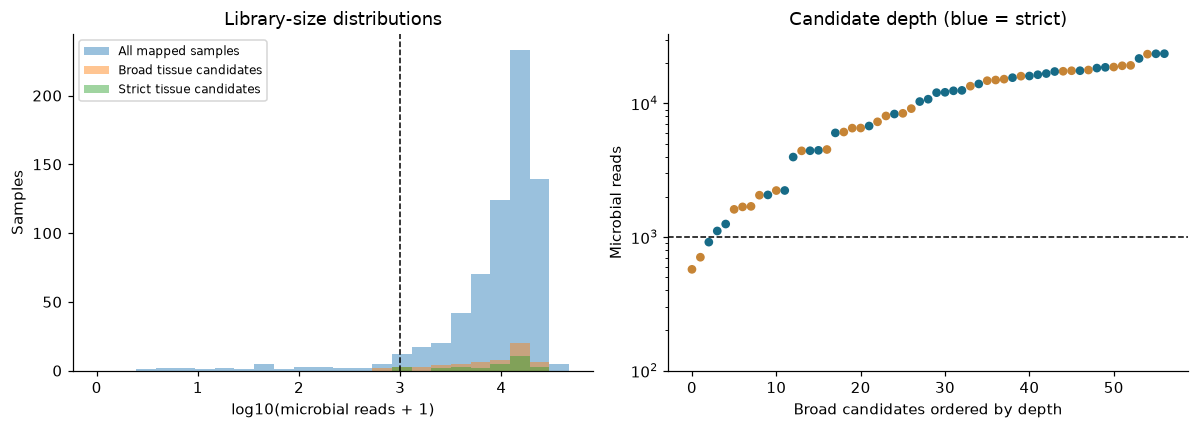

In [10]:
feature_rows = []
feature_sums = np.asarray(mat.sum(axis=1)).ravel()
for fid, meta, total in zip(
    otu.ids(axis="observation"), otu.metadata(axis="observation"), feature_sums
):
    tax = (meta or {}).get("taxonomy", [])
    if isinstance(tax, str):
        tax = tax.split(";")
    tax = [str(x).strip() for x in tax]
    joined = ";".join(tax)
    first = tax[0] if tax else "unassigned"
    domain = re.sub(r"^[a-z]__", "", first).casefold()
    organelle = bool(re.search(r"mitochondri|chloroplast", joined, re.I))
    target = domain in {"bacteria", "archaea"} and not organelle
    feature_rows.append(
        dict(
            feature_id=fid,
            domain=first,
            taxonomy=joined,
            total_reads=int(total),
            annotated_organelle=organelle,
            retain=target,
            reason=(
                "target prokaryote"
                if target
                else (
                    "annotated organelle"
                    if organelle
                    else "unresolved or non-target domain"
                )
            ),
        )
    )
taxonomy_df = pd.DataFrame(feature_rows).set_index("feature_id")
taxonomy_df.to_csv(ROOT / "results/qc/feature_taxonomy_audit.tsv", sep="\t")
display(
    taxonomy_df.groupby(["domain", "retain"]).agg(
        features=("total_reads", "size"), reads=("total_reads", "sum")
    )
)
keep_features = taxonomy_df.index[taxonomy_df["retain"]].tolist()
assert keep_features
microbial = otu.filter(keep_features, axis="observation", inplace=False)
source_depth = pd.Series(otu.sum(axis="sample"), index=otu.ids(), dtype="int64")
filtered_depth = pd.Series(
    microbial.sum(axis="sample"), index=microbial.ids(), dtype="int64"
)
qc = pd.DataFrame(audit).set_index("sample_id")
qc["in_biom"] = qc.index.isin(biom_ids)
qc["source_biom_reads"] = source_depth.reindex(qc.index).astype("Int64")
qc["microbial_reads"] = filtered_depth.reindex(qc.index).astype("Int64")
qc["removed_feature_reads"] = qc["source_biom_reads"] - qc["microbial_reads"]
qc["removed_read_fraction"] = (
    qc["removed_feature_reads"] / qc["source_biom_reads"]
).astype("Float64")
qc["reported_total_read_depth"] = pd.to_numeric(
    qc["reported_total_read_depth"], errors="coerce"
)
qc["source_depth_exceeds_reported_depth"] = (
    qc["source_biom_reads"].gt(qc["reported_total_read_depth"]).fillna(False)
)
qc["empty_after_taxonomy"] = qc["in_biom"] & qc["microbial_reads"].eq(0).fillna(False)
qc["biom_presence"] = np.where(qc["in_biom"], "present", "absent")
qc["postfilter_depth"] = qc["microbial_reads"]
print(
    "Metadata candidates absent from BIOM:",
    qc.loc[
        (qc["strict_candidate"] | qc["broad_candidate"]) & ~qc["in_biom"]
    ].index.tolist(),
)
print("Samples with zero microbial reads:", int(qc["empty_after_taxonomy"].sum()))
display(
    qc.loc[
        qc["broad_candidate"],
        ["source_biom_reads", "microbial_reads", "removed_read_fraction"],
    ].describe()
)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, mask in [
    ("All mapped samples", qc["in_biom"]),
    ("Broad tissue candidates", qc["broad_candidate"] & qc["in_biom"]),
    ("Strict tissue candidates", qc["strict_candidate"] & qc["in_biom"]),
]:
    values = qc.loc[mask, "microbial_reads"].dropna().to_numpy(dtype=float)
    axes[0].hist(
        np.log10(values + 1),
        bins=np.linspace(0, np.log10(float(qc["microbial_reads"].max()) + 1) + 0.1, 25),
        alpha=0.45,
        label=label,
    )
axes[0].axvline(np.log10(1001), color="black", linestyle="--", linewidth=1)
axes[0].set(
    xlabel="log10(microbial reads + 1)",
    ylabel="Samples",
    title="Library-size distributions",
)
axes[0].legend(fontsize=8)
depth_plot = qc.loc[qc["broad_candidate"] & qc["in_biom"]].sort_values(
    "microbial_reads"
)
axes[1].scatter(
    range(len(depth_plot)),
    depth_plot["microbial_reads"],
    c=["#176B87" if x else "#C68435" for x in depth_plot["strict_candidate"]],
    s=22,
)
axes[1].axhline(1000, color="black", linestyle="--", linewidth=1)
axes[1].set_yscale("log")
axes[1].set_ylim(bottom=100, top=float(depth_plot["microbial_reads"].max()) * 1.4)
axes[1].set(
    xlabel="Broad candidates ordered by depth",
    ylabel="Microbial reads",
    title="Candidate depth (blue = strict)",
)
fig.tight_layout()
fig.savefig(ROOT / "results/figures/library_size_qc.png", dpi=180)
plt.show()

### 4.2 Mitochondrial identification checks

The source flag compares the expected colony mitotype with the most abundant host mitotype in a sample. The [author's QC script](https://github.com/zaneveld/GCMP_Australia_Coevolution/blob/fba13cd74d717727d1990e5848d9c86695454a90/11_quality_control_via_mitos/procedure/2_reclassify_host_taxonomy.sh) removes `no` flags. Our conservative primary set requires `yes`; flagged and unknown cases are retained separately for sensitivity analysis. Small mitochondrial counts make disagreement uncertain and do not independently prove contamination. No host species labels are reassigned.

In [11]:
md_index = pd.DataFrame(cleaned).set_index("#SampleID")
mito_columns = [
    "colony_mitotype",
    "ratio_of_colony_mitoype_to_sample_mitotype",
    "ratio_of_colony_mitoype_to_total_mitos",
    "total_host_mitochondrial_count",
    "local_colony_name",
    "collection_id",
    "reef_name",
    "date",
]
for col in mito_columns:
    qc[col] = md_index[col].reindex(qc.index)
for col in mito_columns[:4]:
    if col != "colony_mitotype":
        qc[col] = pd.to_numeric(qc[col], errors="coerce")
qc["mitotype_pass"] = qc["mitotype_match"].eq("yes")
qc["mitotype_review_reason"] = np.select(
    [
        qc["mitotype_match"].eq("no"),
        ~qc["mitotype_match"].isin(["yes", "no"]),
        qc["total_host_mitochondrial_count"].lt(10),
    ],
    [
        "discordant expected/dominant mitotype; hold out from primary",
        "missing or indeterminate flag; hold out from primary",
        "agreement with fewer than 10 host reads; low-support review flag",
    ],
    default="agreement",
)
review = qc.loc[
    qc["broad_candidate"] & ~qc["mitotype_pass"],
    [
        "canonical_species",
        "colony_id",
        "mitotype_match",
        "total_host_mitochondrial_count",
        "ratio_of_colony_mitoype_to_total_mitos",
        "microbial_reads",
        "strict_candidate",
        "mitotype_review_reason",
    ],
]
review.to_csv(ROOT / "results/qc/mitochondrial_disagreement_review.tsv", sep="\t")
display(review)
# A threshold of 10 is only a reporting flag, not an additional inclusion rule.
print(
    "Strict candidate disagreements:",
    int((qc["strict_candidate"] & ~qc["mitotype_pass"]).sum()),
)
print("Broad candidate disagreements:", len(review))

,canonical_species,colony_id,mitotype_match,total_host_mitochondrial_count,ratio_of_colony_mitoype_to_total_mitos,microbial_reads,strict_candidate,mitotype_review_reason
sample_id,,,,,,,,
E10.Sty.pist.1.20150628.T,Stylophora pistillata,E10.10.Sty.pist.1.20150628,no,23.0,0.0000,16393,True,discordant expected/dominant mitotype; hold out from primary
E3.6.Acr.hyac.1.20150105.T,Acropora hyacinthus,E3.6.Acr.hyac.1.20150105,no,13.0,0.0000,4416,False,discordant expected/dominant mitotype; hold out from primary
E3.6.Acr.hyac.1.20150106.T,Acropora hyacinthus,E3.6.Acr.hyac.1.20150106,no,47.0,0.1277,19257,False,discordant expected/dominant mitotype; hold out from primary
E3.6.Acr.hyac.1.20150118.T,Acropora hyacinthus,E3.6.Acr.hyac.1.20150118,no,1060.0,0.0000,6544,False,discordant expected/dominant mitotype; hold out from primary
E3.6.Acr.hyac.1.20150120.T,Acropora hyacinthus,E3.6.Acr.hyac.1.20150120,no,1.0,0.0000,573,False,discordant expected/dominant mitotype; hold out from primary
E3.6.Acr.hyac.2.20150105.T,Acropora hyacinthus,E3.6.Acr.hyac.2.20150105,no,22.0,0.0000,15193,False,discordant expected/dominant mitotype; hold out from primary
E3.6.Acr.hyac.2.20150106.T,Acropora hyacinthus,E3.6.Acr.hyac.2.20150106,no,86.0,0.0000,23376,False,discordant expected/dominant mitotype; hold out from primary
E3.6.Acr.hyac.2.20150121.T,Acropora hyacinthus,E3.6.Acr.hyac.2.20150121,no,1052.0,0.0000,1681,False,discordant expected/dominant mitotype; hold out from primary
E3.6.Acr.hyac.3.20150105.T,Acropora hyacinthus,E3.6.Acr.hyac.3.20150105,no,10.0,0.0000,17781,False,discordant expected/dominant mitotype; hold out from primary


Strict candidate disagreements: 3
Broad candidate disagreements: 16


### 4.3 Depth thresholds and cohort selection

Use **1,000 microbial reads** as the initial minimum, consistent with the [source study's analysis](https://github.com/zaneveld/GCMP_Australia_Coevolution/blob/fba13cd74d717727d1990e5848d9c86695454a90/3a_adiv_australia_analysis/procedure/adiv_australia_gg_constrained_tree.ipynb). Compare alternative thresholds without selecting them by association-test results. This is a minimum-depth filter, not rarefaction or a claim that diversity is saturated. The primary cohort combines strict metadata criteria and mitotype agreement. Broader health criteria and relaxed mitotype handling are separate sensitivity cohorts.

,scheme,minimum_reads,samples,species,recorded_colonies,species_with_3_recorded_colonies
0,primary_strict_mito_agree,0,26,8,26,3
1,primary_strict_mito_agree,500,26,8,26,3
2,primary_strict_mito_agree,1000,25,8,25,3
3,primary_strict_mito_agree,2000,23,8,23,3
4,primary_strict_mito_agree,5000,19,8,19,2
5,primary_strict_mito_agree,10000,16,8,16,1
6,sensitivity_strict_all_mitotypes,0,29,8,29,4
7,sensitivity_strict_all_mitotypes,500,29,8,29,4
8,sensitivity_strict_all_mitotypes,1000,28,8,28,4
9,sensitivity_strict_all_mitotypes,2000,26,8,26,4


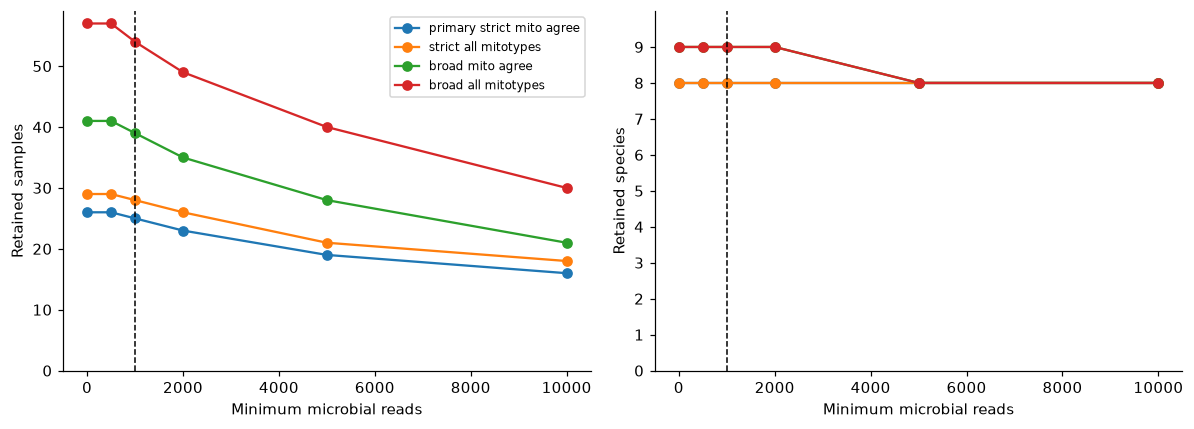

In [12]:
MIN_READS = PROTOCOL["microbiome"]["minimum_reads"]
thresholds = PROTOCOL["microbiome"]["depth_threshold_sensitivity"]
schemes = {
    "primary_strict_mito_agree": qc["strict_candidate"] & qc["mitotype_pass"],
    "sensitivity_strict_all_mitotypes": qc["strict_candidate"],
    "sensitivity_broad_mito_agree": qc["broad_candidate"] & qc["mitotype_pass"],
    "sensitivity_broad_all_mitotypes": qc["broad_candidate"],
}
retention = []
for name, eligible in schemes.items():
    for cutoff in thresholds:
        chosen = qc.loc[
            eligible
            & qc["in_biom"]
            & qc["microbial_reads"].ge(max(cutoff, 1)).fillna(False)
        ]
        retention.append(
            dict(
                scheme=name,
                minimum_reads=cutoff,
                samples=len(chosen),
                species=chosen["canonical_species"].nunique(),
                recorded_colonies=chosen["colony_id"].nunique(),
                species_with_3_recorded_colonies=int(
                    (
                        chosen.groupby("canonical_species")["colony_id"].nunique() >= 3
                    ).sum()
                ),
            )
        )
retention_df = pd.DataFrame(retention)
retention_df.to_csv(
    ROOT / "results/qc/depth_threshold_sensitivity.tsv", sep="\t", index=False
)
display(retention_df)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, group in retention_df.groupby("scheme", sort=False):
    label = name.replace("sensitivity_", "").replace("_", " ")
    axes[0].plot(group["minimum_reads"], group["samples"], marker="o", label=label)
    axes[1].plot(group["minimum_reads"], group["species"], marker="o", label=label)
for ax in axes:
    ax.axvline(MIN_READS, color="black", linestyle="--", linewidth=1)
    ax.set_xlabel("Minimum microbial reads")
    ax.set_ylim(bottom=0)
axes[0].set_ylabel("Retained samples")
axes[1].set_ylabel("Retained species")
axes[1].set_ylim(0, retention_df["species"].max() + 1)
axes[1].set_yticks(range(0, int(retention_df["species"].max()) + 1))
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(ROOT / "results/figures/depth_threshold_sensitivity.png", dpi=180)
plt.show()

In [13]:
for name, eligible in schemes.items():
    qc[name] = (
        eligible & qc["in_biom"] & qc["microbial_reads"].ge(MIN_READS).fillna(False)
    )
qc["primary_exclusion_reasons"] = qc["exclusion_reasons"].fillna("").astype(str)
for mask, reason in [
    (~qc["in_biom"], "absent from BIOM"),
    (
        qc["in_biom"] & qc["microbial_reads"].lt(MIN_READS).fillna(False),
        "fewer than 1000 microbial reads",
    ),
    (~qc["mitotype_pass"], "mitotype agreement not confirmed"),
]:
    qc.loc[mask, "primary_exclusion_reasons"] = qc.loc[
        mask, "primary_exclusion_reasons"
    ].map(lambda s: "; ".join(x for x in [s, reason] if x))
qc.to_csv(ROOT / "data/processed/sample_qc_with_biom.tsv", sep="\t")
primary = qc.loc[qc["primary_strict_mito_agree"]].copy()
print(
    "Primary cohort:",
    len(primary),
    "samples,",
    primary["canonical_species"].nunique(),
    "species.",
)

Primary cohort: 25 samples, 8 species.


### 4.4 Processed counts and sample coverage

Export unrarefied integer counts and matching taxonomy. Remove only features absent from each cohort; apply no prevalence filter. A separate cohort retains unassigned non-organelle OTUs. Recorded colony IDs and collection events do not establish biological independence; samples within a species do not add species-level NLR replicates.

In [14]:
# Retain unresolved non-organelle OTUs in a separate taxonomy sensitivity cohort.
permissive_ids = taxonomy_df.index[
    ~taxonomy_df["annotated_organelle"]
    & taxonomy_df["domain"].isin(["k__Bacteria", "k__Archaea", "Unassigned"])
].tolist()
permissive = otu.filter(permissive_ids, axis="observation", inplace=False)
permissive_depth = pd.Series(
    permissive.sum(axis="sample"), index=permissive.ids(), dtype="int64"
)
qc["reads_including_unassigned"] = permissive_depth.reindex(qc.index).astype("Int64")
taxonomy_sensitivity = []
for scope, eligible in schemes.items():
    for label, depths in [
        ("assigned prokaryotes", qc["microbial_reads"]),
        ("including unassigned", qc["reads_including_unassigned"]),
    ]:
        retained = qc.loc[eligible & qc["in_biom"] & depths.ge(MIN_READS).fillna(False)]
        taxonomy_sensitivity.append(
            dict(
                scheme=scope,
                taxonomy_policy=label,
                samples=len(retained),
                species=retained["canonical_species"].nunique(),
            )
        )
pd.DataFrame(taxonomy_sensitivity).to_csv(
    ROOT / "results/qc/taxonomy_filter_sensitivity.tsv", sep="\t", index=False
)
display(pd.DataFrame(taxonomy_sensitivity))
qc["sensitivity_strict_mito_with_unassigned"] = (
    qc["strict_candidate"]
    & qc["mitotype_pass"]
    & qc["in_biom"]
    & qc["reads_including_unassigned"].ge(MIN_READS).fillna(False)
)
qc.to_csv(ROOT / "data/processed/sample_qc_with_biom.tsv", sep="\t")

,scheme,taxonomy_policy,samples,species
0,primary_strict_mito_agree,assigned prokaryotes,25,8
1,primary_strict_mito_agree,including unassigned,26,8
2,sensitivity_strict_all_mitotypes,assigned prokaryotes,28,8
3,sensitivity_strict_all_mitotypes,including unassigned,29,8
4,sensitivity_broad_mito_agree,assigned prokaryotes,39,9
5,sensitivity_broad_mito_agree,including unassigned,40,9
6,sensitivity_broad_all_mitotypes,assigned prokaryotes,54,9
7,sensitivity_broad_all_mitotypes,including unassigned,55,9


In [15]:
cohort_paths = {}
for name in schemes:
    subset = qc.loc[qc[name]].copy()
    sample_order = subset.index.tolist()
    assert sample_order and not subset.index.duplicated().any()
    sub = microbial.filter(sample_order, axis="sample", inplace=False).sort_order(
        sample_order, axis="sample"
    )
    sub = sub.remove_empty(axis="observation", inplace=False)
    out = ROOT / "data/processed" / name
    out.mkdir(exist_ok=True)
    subset.to_csv(out / "sample_metadata.tsv", sep="\t")
    with biom_open(str(out / "counts.biom"), "w") as handle:
        sub.to_hdf5(handle, "bio-project data preparation")
    counts_df = sub.to_dataframe(dense=True).astype("int64")
    assert list(counts_df.columns) == sample_order
    counts_df.to_csv(out / "counts.tsv.gz", sep="\t", compression="gzip")
    taxonomy_df.loc[sub.ids(axis="observation")].to_csv(out / "taxonomy.tsv", sep="\t")
    check = load_table(str(out / "counts.biom"))
    assert list(check.ids()) == sample_order
    assert np.array_equal(
        check.sum(axis="sample"), subset["microbial_reads"].to_numpy(dtype=float)
    )
    cohort_paths[name] = dict(
        samples=sub.shape[1],
        features=sub.shape[0],
        species=subset["canonical_species"].nunique(),
        path=str(out.relative_to(ROOT)),
    )

In [16]:
name = "sensitivity_strict_mito_with_unassigned"
subset = qc.loc[qc[name]].copy()
sample_order = subset.index.tolist()
sub = (
    permissive.filter(sample_order, axis="sample", inplace=False)
    .sort_order(sample_order, axis="sample")
    .remove_empty(axis="observation", inplace=False)
)
out = ROOT / "data/processed" / name
out.mkdir(exist_ok=True)
subset.to_csv(out / "sample_metadata.tsv", sep="\t")
with biom_open(str(out / "counts.biom"), "w") as handle:
    sub.to_hdf5(handle, "bio-project taxonomy sensitivity")
sub.to_dataframe(dense=True).astype("int64").to_csv(
    out / "counts.tsv.gz", sep="\t", compression="gzip"
)
taxonomy_df.loc[sub.ids(axis="observation")].to_csv(out / "taxonomy.tsv", sep="\t")
check = load_table(str(out / "counts.biom"))
assert list(check.ids()) == sample_order
assert np.array_equal(
    check.sum(axis="sample"), subset["reads_including_unassigned"].to_numpy(dtype=float)
)
cohort_paths[name] = dict(
    samples=sub.shape[1],
    features=sub.shape[0],
    species=subset["canonical_species"].nunique(),
    path=str(out.relative_to(ROOT)),
)

,metadata_strict,present_strict,depth_pass_strict,primary_samples,recorded_colony_ids,collection_events,sites,expeditions,minimum_reads,median_reads,broad_mito_agree_samples,broad_all_mitotypes_samples,fewer_than_3_recorded_colonies
species,,,,,,,,,,,,,
Acropora hyacinthus,3,3,3,2,2,1,1,1,10325.0,11217.5,7,20,True
Caulastraea furcata,1,1,1,1,1,1,1,1,10753.0,10753.0,1,1,True
Echinopora horrida,0,0,0,0,0,0,0,0,NaN,NaN,1,1,True
Galaxea fascicularis,2,2,2,2,2,2,1,1,12429.0,17976.0,2,2,True
Isopora palifera,4,4,4,4,4,3,2,2,15582.0,17447.5,4,4,False
Pocillopora damicornis,9,9,8,7,7,6,4,3,1110.0,6017.0,7,8,False
Porites cylindrica,2,2,2,2,2,2,1,1,13986.0,16305.0,5,5,True
Stylophora pistillata,6,6,6,5,5,3,2,2,1251.0,3968.0,8,9,False
Turbinaria reniformis,2,2,2,2,2,2,1,1,12517.0,14277.0,4,4,True


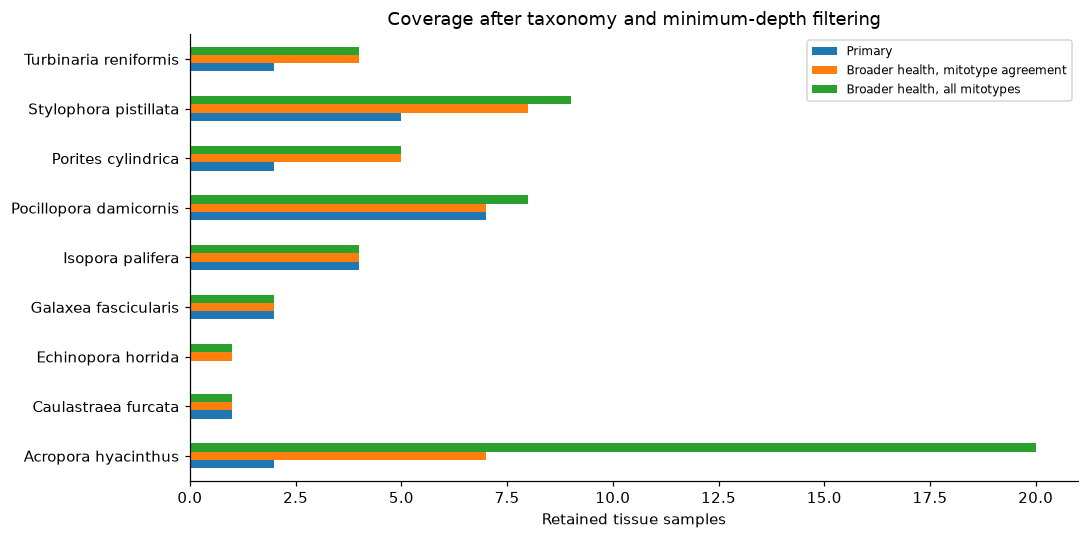

In [17]:
coverage_rows = []
for species in overlap:
    all_rows = qc.loc[qc["canonical_species"] == species]
    selected = all_rows.loc[all_rows["primary_strict_mito_agree"]]
    coverage_rows.append(
        dict(
            species=species,
            metadata_strict=int(all_rows["strict_candidate"].sum()),
            present_strict=int(
                (all_rows["strict_candidate"] & all_rows["in_biom"]).sum()
            ),
            depth_pass_strict=int(
                (
                    all_rows["strict_candidate"]
                    & all_rows["microbial_reads"].ge(MIN_READS).fillna(False)
                ).sum()
            ),
            primary_samples=len(selected),
            recorded_colony_ids=selected["colony_id"].nunique(),
            collection_events=selected["collection_id"].nunique(),
            sites=selected["site"].nunique(),
            expeditions=selected["expedition"].nunique(),
            minimum_reads=(
                int(selected["microbial_reads"].min()) if len(selected) else None
            ),
            median_reads=(
                float(selected["microbial_reads"].median()) if len(selected) else None
            ),
            broad_mito_agree_samples=int(
                all_rows["sensitivity_broad_mito_agree"].sum()
            ),
            broad_all_mitotypes_samples=int(
                all_rows["sensitivity_broad_all_mitotypes"].sum()
            ),
            fewer_than_3_recorded_colonies=selected["colony_id"].nunique() < 3,
        )
    )
coverage_df = pd.DataFrame(coverage_rows).set_index("species")
coverage_df.to_csv(ROOT / "results/tables/species_coverage_after_biom_qc.tsv", sep="\t")
display(coverage_df)
primary.groupby(
    ["canonical_species", "expedition", "site", "collection_id"], dropna=False
).agg(
    samples=("colony_id", "size"), recorded_colony_ids=("colony_id", "nunique")
).to_csv(
    ROOT / "results/qc/primary_species_site_coverage.tsv", sep="\t"
)
fig, ax = plt.subplots(figsize=(10, 5))
coverage_df[
    ["primary_samples", "broad_mito_agree_samples", "broad_all_mitotypes_samples"]
].plot.barh(ax=ax)
ax.set(
    xlabel="Retained tissue samples",
    ylabel="",
    title="Coverage after taxonomy and minimum-depth filtering",
)
ax.legend(
    ["Primary", "Broader health, mitotype agreement", "Broader health, all mitotypes"],
    fontsize=8,
)
fig.tight_layout()
fig.savefig(ROOT / "results/figures/species_coverage_after_qc.png", dpi=180)
plt.show()

In [18]:
biom_summary = dict(
    source_features=int(otu.shape[0]),
    source_samples=int(otu.shape[1]),
    microbial_features=int(microbial.shape[0]),
    metadata_only_samples=len(metadata_ids - biom_ids),
    biom_only_samples=len(biom_ids - metadata_ids),
    minimum_reads=MIN_READS,
    cohorts=cohort_paths,
    primary_species_with_3_recorded_colonies=int(
        (coverage_df["recorded_colony_ids"] >= 3).sum()
    ),
    normalization="unrarefied counts; no diversity normalization yet",
    mitochondrial_policy="require yes in primary; retain no/unknown only in sensitivity",
    phylogeny_status="species-level phylogeny still required",
)
(ROOT / "results/qc/biom_preparation_summary.json").write_text(
    json.dumps(biom_summary, indent=2) + "\n"
)
(ROOT / "config/microbiome_filter_parameters.json").write_text(
    json.dumps(
        dict(
            minimum_reads=MIN_READS,
            threshold_sensitivity=thresholds,
            primary_health="strict",
            primary_mitotype="yes",
            retained_domains=["Bacteria", "Archaea"],
            remove_annotated_organelles=True,
            rarefaction=False,
            prevalence_filter=False,
        ),
        indent=2,
    )
    + "\n"
)
print(json.dumps(biom_summary, indent=2))

{
  "source_features": 129305,
  "source_samples": 692,
  "microbial_features": 108053,
  "metadata_only_samples": 3,
  "biom_only_samples": 0,
  "minimum_reads": 1000,
  "cohorts": {
    "primary_strict_mito_agree": {
      "samples": 25,
      "features": 10316,
      "species": 8,
      "path": "data/processed/primary_strict_mito_agree"
    },
    "sensitivity_strict_all_mitotypes": {
      "samples": 28,
      "features": 10514,
      "species": 8,
      "path": "data/processed/sensitivity_strict_all_mitotypes"
    },
    "sensitivity_broad_mito_agree": {
      "samples": 39,
      "features": 11656,
      "species": 9,
      "path": "data/processed/sensitivity_broad_mito_agree"
    },
    "sensitivity_broad_all_mitotypes": {
      "samples": 54,
      "features": 12720,
      "species": 9,
      "path": "data/processed/sensitivity_broad_all_mitotypes"
    },
    "sensitivity_strict_mito_with_unassigned": {
      "samples": 26,
      "features": 11427,
      "species": 8,
      "pa

### 4.5 Preparation checks and frozen input verification

Validate preparation outputs and every frozen input representation before candidate identification. Metadata-only candidate tables remain an audit trail; count-validated cohorts are the inputs to later analyses. A species-resolved phylogeny and validated coral positive controls remain unavailable.

In [19]:
readiness = dict(
    metadata_records=len(raw),
    genome_sets=len(genomes),
    overlap_species=len(overlap),
    strict_tissue_samples=len(strict),
    strict_species=len({r["canonical_species"] for r in strict}),
    broad_tissue_samples=len(broad),
    broad_species=len({r["canonical_species"] for r in broad}),
    strict_mitotype_agreement_samples=sum(r["mitotype_match"] == "yes" for r in strict),
    species_with_unambiguous_source_tree_mapping=sum(
        r["mapping_status"] == "unambiguous source-label mapping" for r in tree_map
    ),
    hmm_models=len(model_rows),
    reference_proteins=len(refs),
    new_conda_environment_created=True,
    biom_matrix_qc="completed; see biom_preparation_summary.json",
    pgls_species_tree="not ready",
    coral_validated_reference_sequences="not yet available",
    primary_count_validated_samples=len(primary),
    primary_count_validated_species=int(primary["canonical_species"].nunique()),
    interpretation="metadata candidates and count-validated cohorts are reported separately",
)
(ROOT / "results/qc/preparation_summary.json").write_text(
    json.dumps(readiness, indent=2) + "\n"
)
print(json.dumps(readiness, indent=2))
assert len(audit) == len(raw)
assert {r["sample_id"] for r in strict} <= {r["sample_id"] for r in broad}
assert all(r["canonical_species"] in genome_names for r in strict)
assert len(quality) == 40 and len(model_rows) >= 15 and len(refs) == 5
print("Preparation checks passed. Raw source files were not overwritten.")

{
  "metadata_records": 695,
  "genome_sets": 40,
  "overlap_species": 9,
  "strict_tissue_samples": 29,
  "strict_species": 8,
  "broad_tissue_samples": 57,
  "broad_species": 9,
  "strict_mitotype_agreement_samples": 26,
  "species_with_unambiguous_source_tree_mapping": 4,
  "hmm_models": 15,
  "reference_proteins": 5,
  "new_conda_environment_created": true,
  "biom_matrix_qc": "completed; see biom_preparation_summary.json",
  "pgls_species_tree": "not ready",
  "coral_validated_reference_sequences": "not yet available",
  "primary_count_validated_samples": 25,
  "primary_count_validated_species": 8,
  "interpretation": "metadata candidates and count-validated cohorts are reported separately"
}
Preparation checks passed. Raw source files were not overwritten.


In [20]:
# Detect changes to the frozen cohort and reference representations.
assert MIN_READS == PROTOCOL["microbiome"]["minimum_reads"]
for name, expected in PROTOCOL["cohorts"].items():
    actual = read_tsv(ROOT / expected["path"] / "sample_metadata.tsv")
    assert sorted(r["sample_id"] for r in actual) == expected["sample_ids"], name
    assert len(actual) == expected["expected_samples"], name
    assert (
        len({r["canonical_species"] for r in actual}) == expected["expected_species"]
    ), name
for record in read_tsv(ROOT / "config/analysis_inputs_v1.tsv"):
    data = (ROOT / record["path"]).read_bytes()
    if record["hash_mode"] == "gzip_decompressed_bytes":
        data = gzip.decompress(data)
    assert hashlib.sha256(data).hexdigest() == record["sha256"], record["path"]
print("Frozen v1 inputs, cohort memberships and depth settings verified.")

Frozen v1 inputs, cohort memberships and depth settings verified.


<a id="nlr"></a>
## 5 NLR candidate identification

### 5.1 Three species technical pilot

Run the frozen rule on *P. damicornis*, *S. pistillata* and *I. palifera*. GTF mappings define loci; the longest eligible isoform defines each primary count. HMMER uses model GA thresholds and at least 50% model coverage. BLAST provides supporting evidence only. Verified HMMER outputs are reused when inputs, commands, tool versions and output hashes match.

In [21]:
for script in ["test_nlr_pilot.py", "run_nlr_pilot.py", "summarize_nlr_pilot.py"]:
    completed = subprocess.run(
        [sys.executable, str(ROOT / "scripts" / script)],
        cwd=ROOT,
        text=True,
        capture_output=True,
    )
    if completed.returncode:
        print(completed.stdout)
        print(completed.stderr)
        completed.check_returncode()
    print(script + ": passed")

pilot_path = ROOT / "results/nlr_pilot_v1"
pilot_validation = json.loads((pilot_path / "validation.json").read_text())
assert pilot_validation["pilot_gate"] == "pass"
assert not pilot_validation["association_tests_run"]
assert (
    hashlib.sha256((ROOT / "scripts/run_nlr_pilot.py").read_bytes()).hexdigest()
    == pilot_validation["source_script_sha256"]
)
for relative_path, expected_sha in pilot_validation["output_sha256"].items():
    assert (
        hashlib.sha256((ROOT / relative_path).read_bytes()).hexdigest() == expected_sha
    )
pilot_summary = pd.read_csv(pilot_path / "species_summary.tsv", sep="\t")
display(
    pilot_summary[
        [
            "species",
            "annotated_genes",
            "protein_isoforms",
            "mapping_percent",
            "canonical",
            "nacht",
            "nb_arc",
            "any_isoform_canonical",
            "canonical_per_10000_genes",
            "canonical_with_reference_hit",
        ]
    ]
)
print("Pilot checks passed. Association tests follow in Section 7.")

test_nlr_pilot.py: passed


run_nlr_pilot.py: passed


summarize_nlr_pilot.py: passed


,species,annotated_genes,protein_isoforms,mapping_percent,canonical,nacht,nb_arc,any_isoform_canonical,canonical_per_10000_genes,canonical_with_reference_hit
0,Pocillopora damicornis,25858,30134,100.0,18,60,11,18,6.9611,18
1,Stylophora pistillata,30756,35500,100.0,38,100,15,38,12.3553,38
2,Isopora palifera,25181,28399,100.0,29,69,8,29,11.5166,29


Pilot checks passed. Association tests follow in Section 7.


### 5.2 Pilot counts and reference controls

Counts describe candidate architecture, not validated immune function. NACHT, canonical and NB-ARC categories overlap. The [Hydra reference](https://doi.org/10.1093/molbev/msq349) is expected to contain DEATH–NACHT without LRR; APAF1 is an NB-ARC comparator. Coral examples illustrate the rule and are selected deterministically near the median candidate length.

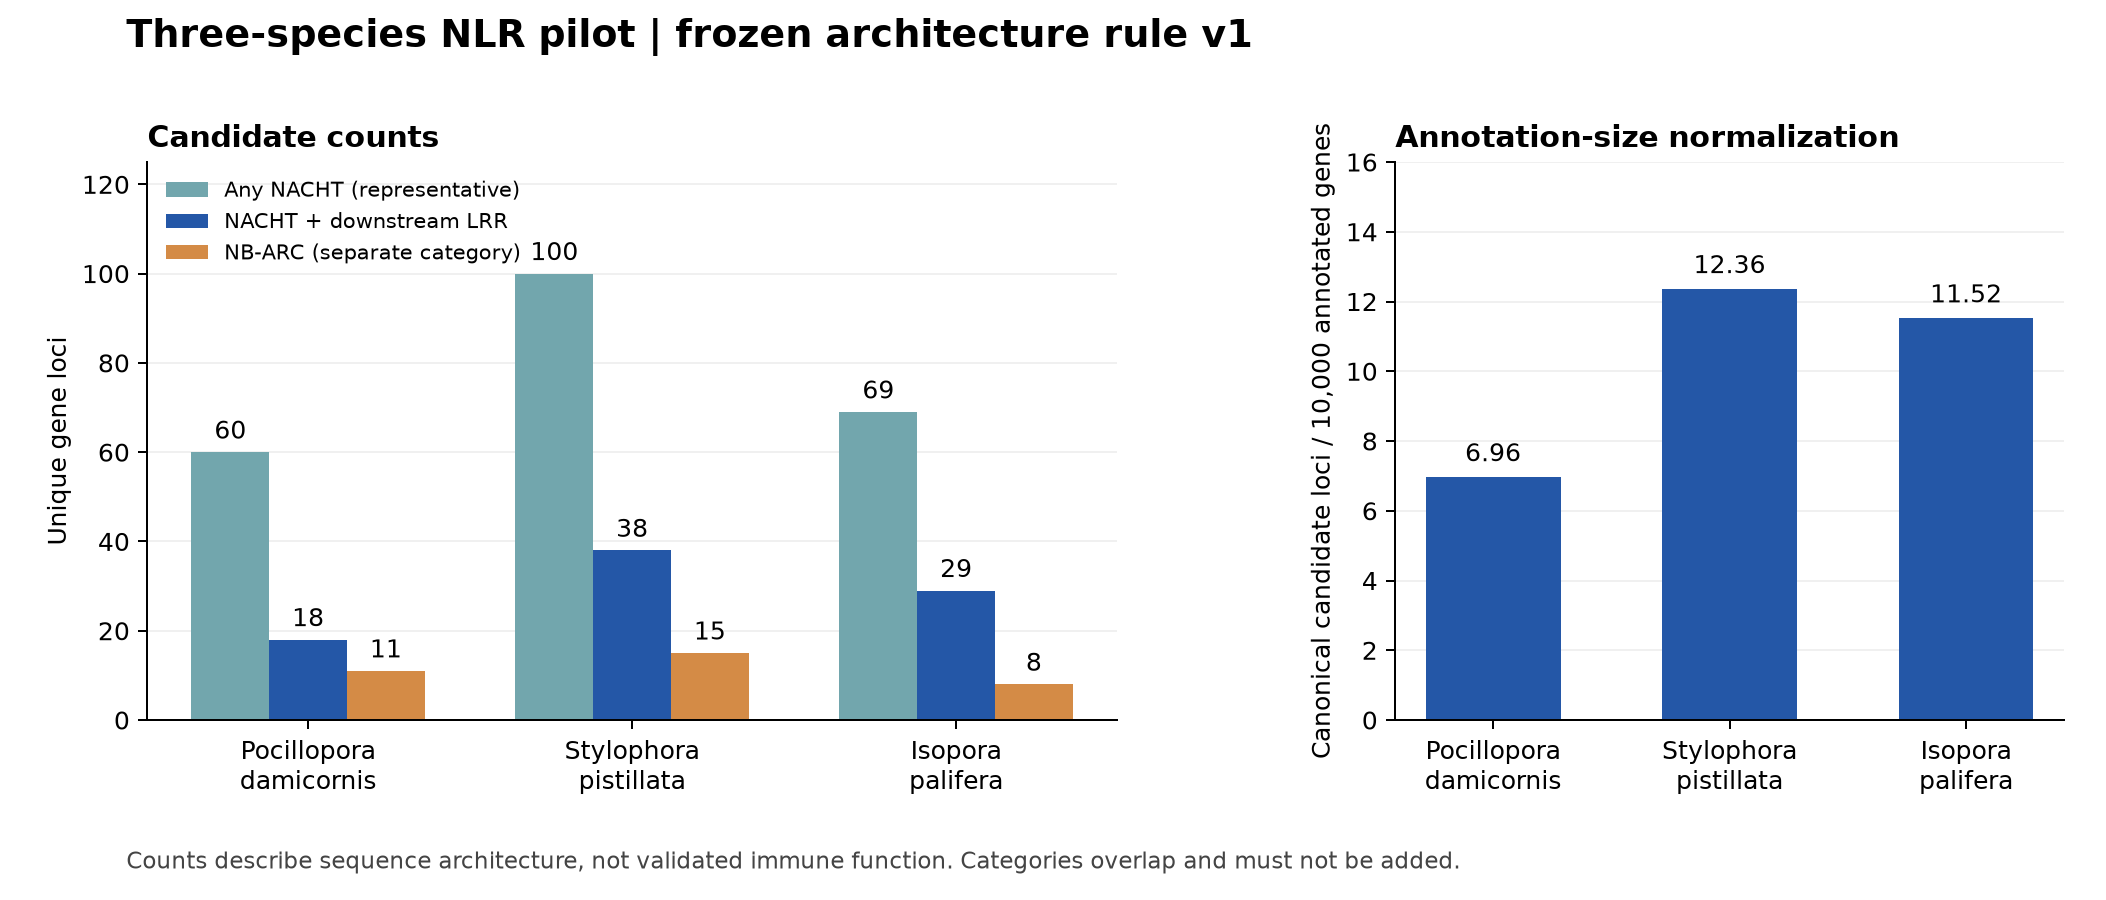

,protein_id,length,canonical,nacht,nb_arc,lrr_domains
0,Q9Y239,953,True,True,False,3
1,Q9HC29,1040,True,True,False,3
2,Q96P20,1036,True,True,False,5
3,ADU79234.1,688,False,True,False,0
4,O14727,1248,False,False,True,0


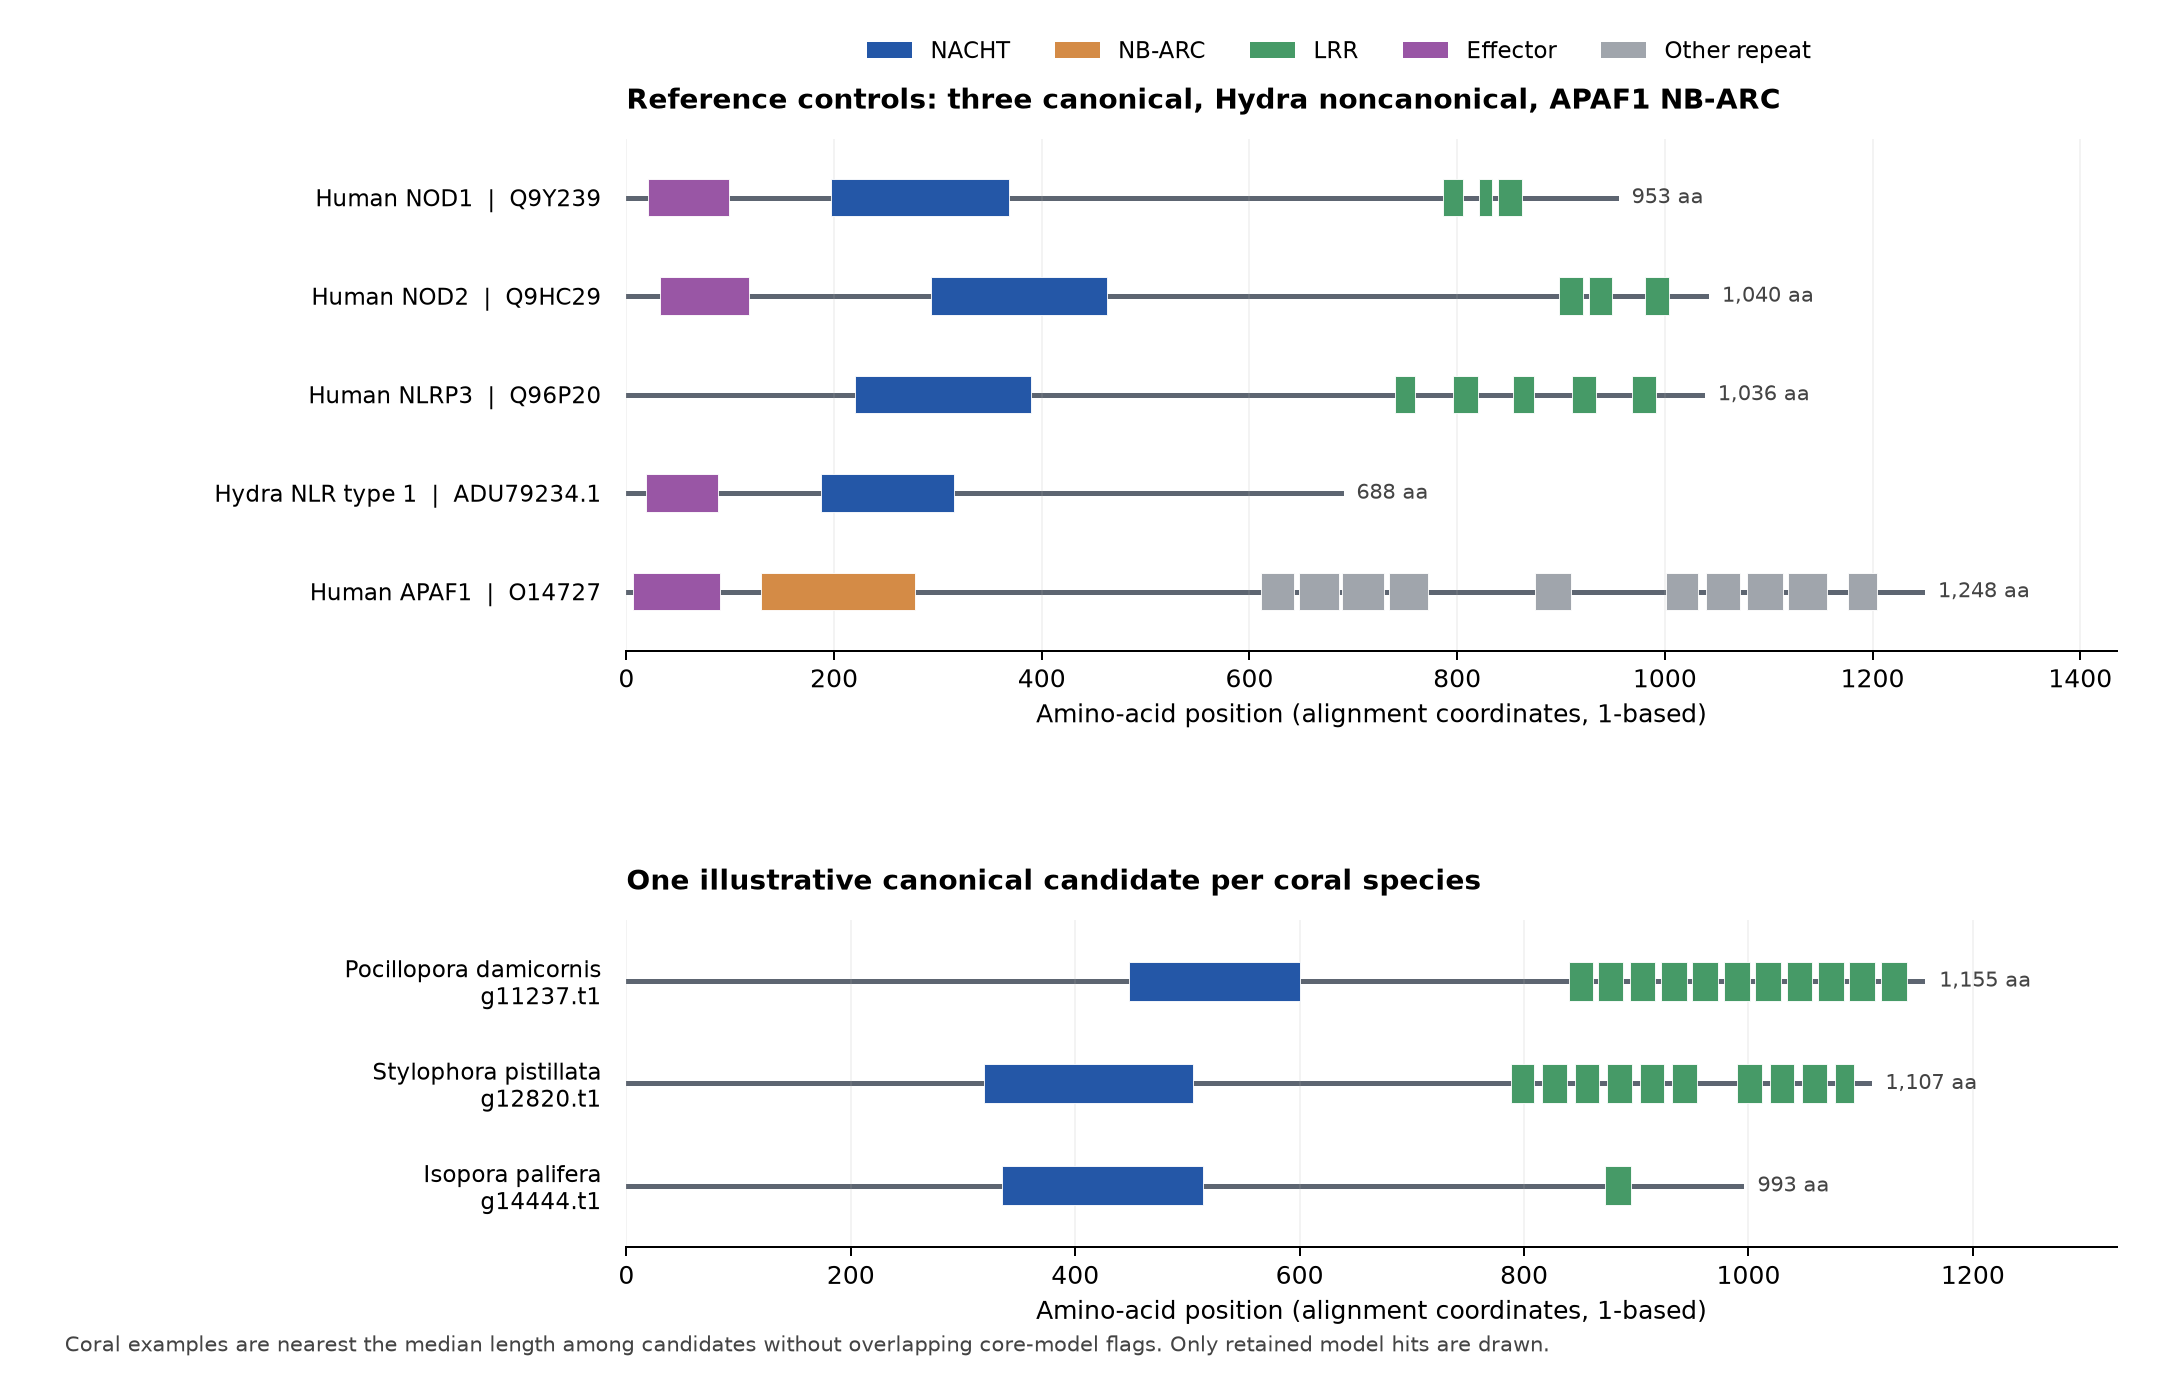

In [22]:
display(Image(filename=str(ROOT / "results/figures/nlr_pilot_counts.png")))
pilot_controls = pd.read_csv(pilot_path / "control_classification.tsv", sep="\t")
display(
    pilot_controls[
        ["protein_id", "length", "canonical", "nacht", "nb_arc", "lrr_domains"]
    ]
)
display(Image(filename=str(ROOT / "results/figures/nlr_pilot_architectures.png")))

### 5.3 Pilot candidate review

Five pilot candidates have overlapping NACHT/NB-ARC assignments in the same region and remain single counted loci. All 85 canonical representatives have reference-panel BLAST hits, which do not establish orthology or function. The full run below applies the unchanged rule.

In [23]:
pilot_review = pd.read_csv(pilot_path / "overlapping_core_review.tsv", sep="\t")
display(
    pilot_review[
        [
            "species",
            "protein_id",
            "model",
            "start",
            "end",
            "bit_score",
            "model_coverage",
        ]
    ]
)
assert pilot_summary["unresolved_genes"].eq(0).all()
assert pilot_summary["canonical"].eq(pilot_summary["any_isoform_canonical"]).all()
assert (
    pilot_summary["canonical"].eq(pilot_summary["canonical_with_reference_hit"]).all()
)
print("Pilot outputs: results/nlr_pilot_v1/")
print("Technical report: reports/nlr_pilot_v1_report.txt")

,species,protein_id,model,start,end,bit_score,model_coverage
0,Pocillopora damicornis,g9923.t1,PF00931.30,301,425,23.9,0.8026
1,Pocillopora damicornis,g9923.t1,PF05729.20,302,457,81.2,0.9940
2,Pocillopora damicornis,g11035.t2,PF00931.30,374,511,25.0,0.8816
3,Pocillopora damicornis,g11035.t2,PF05729.20,387,544,91.4,1.0000
4,Stylophora pistillata,g12263.t1,PF00931.30,300,429,23.6,0.8355
5,Stylophora pistillata,g12263.t1,PF05729.20,306,461,86.7,0.9940
6,Stylophora pistillata,g15771.t1,PF00931.30,439,567,24.0,0.8224
7,Stylophora pistillata,g15771.t1,PF05729.20,444,600,85.4,0.9940
8,Isopora palifera,g17801.t1,PF00931.30,498,624,23.9,0.7895
9,Isopora palifera,g17801.t1,PF05729.20,501,656,94.0,0.9820


Pilot outputs: results/nlr_pilot_v1/
Technical report: reports/nlr_pilot_v1_report.txt


### 5.4 Full identification across nine species

Extend the unchanged v1 rule to the nine species in the frozen name map. Preserve the pilot results and compare their complete protein, locus, domain and count tables with the full run. Eight species enter primary analyses; *Echinopora horrida* is sensitivity-only. Sequence classification does not use microbiome outcomes.

In [24]:
for script in ["run_nlr_full.py", "summarize_nlr_full.py"]:
    completed = subprocess.run(
        [sys.executable, str(ROOT / "scripts" / script)],
        cwd=ROOT,
        text=True,
        capture_output=True,
    )
    if completed.returncode:
        print(completed.stdout)
        print(completed.stderr)
        completed.check_returncode()
    print(script + ": passed")

full_path = ROOT / "results/nlr_full_v1"
full_validation = json.loads((full_path / "validation.json").read_text())
full_completion = json.loads((full_path / "completion.json").read_text())
assert full_validation["analysis_gate"] == "pass"
assert full_completion["status"] == "complete"
assert not full_validation["association_tests_run"]
assert all(
    item["status"] == "identical"
    for item in full_validation["pilot_regression_checks"].values()
)
for relative_path, expected_sha in {
    **full_validation["output_sha256"],
    **full_completion["products_sha256"],
}.items():
    assert (
        hashlib.sha256((ROOT / relative_path).read_bytes()).hexdigest() == expected_sha
    )
full_exposures = pd.read_csv(
    ROOT / "data/processed/nlr_v1/species_exposures.tsv", sep="\t"
)
assert len(full_exposures) == 9 and full_exposures["primary_eligible"].sum() == 8
display(
    full_exposures[
        [
            "species",
            "scope",
            "annotated_genes",
            "canonical",
            "nacht",
            "nb_arc",
            "any_isoform_canonical",
            "canonical_per_10000_genes",
            "busco_complete_percent",
        ]
    ]
)
print(json.dumps(full_completion["metrics"], indent=2))

run_nlr_full.py: passed


summarize_nlr_full.py: passed


,species,scope,annotated_genes,canonical,nacht,nb_arc,any_isoform_canonical,canonical_per_10000_genes,busco_complete_percent
0,Acropora hyacinthus,primary_and_sensitivity,28210,33,85,10,33,11.6980,99.0
1,Caulastraea furcata,primary_and_sensitivity,34778,38,96,16,38,10.9264,95.0
2,Echinopora horrida,sensitivity_only,50984,28,126,26,29,5.4919,92.2
3,Galaxea fascicularis,primary_and_sensitivity,26437,26,64,7,26,9.8347,94.5
4,Isopora palifera,primary_and_sensitivity,25181,29,69,8,29,11.5166,94.0
5,Pocillopora damicornis,primary_and_sensitivity,25858,18,60,11,18,6.9611,99.4
6,Porites cylindrica,primary_and_sensitivity,30453,35,114,28,35,11.4931,97.4
7,Stylophora pistillata,primary_and_sensitivity,30756,38,100,15,38,12.3553,99.2
8,Turbinaria reniformis,primary_and_sensitivity,33091,21,106,13,21,6.3461,92.1


{
  "species": 9,
  "primary_species": 8,
  "protein_isoforms": 325296,
  "annotated_gene_loci": 285748,
  "canonical_candidates": 266,
  "primary_canonical_candidates": 238,
  "nacht_loci": 820,
  "nb_arc_loci": 134,
  "any_isoform_canonical_loci": 267,
  "isoform_sensitive_loci": 1,
  "canonical_overlapping_core_model_flags": 22,
  "canonical_multiple_core_flags": 22,
  "canonical_ambiguous_residue_flags": 0,
  "canonical_partial_gtf_flags": 0,
  "canonical_with_reference_hit": 266,
  "mapping_percent": 100.0,
  "unresolved_loci": 0,
  "source_busco_complete_min": 92.1,
  "pilot_regression": "all five evidence tables identical for the three pilot species",
  "independent_representative_and_architecture_checks": "passed",
  "association_tests_run": false
}


### 5.5 Counts and isoform sensitivity

Counts are unique gene loci. Canonical, NACHT and NB-ARC categories overlap and must not be summed. The primary exposure uses the longest eligible isoform; the alternate exposure uses any eligible isoform. Reference BLAST evidence supports review and does not determine inclusion.

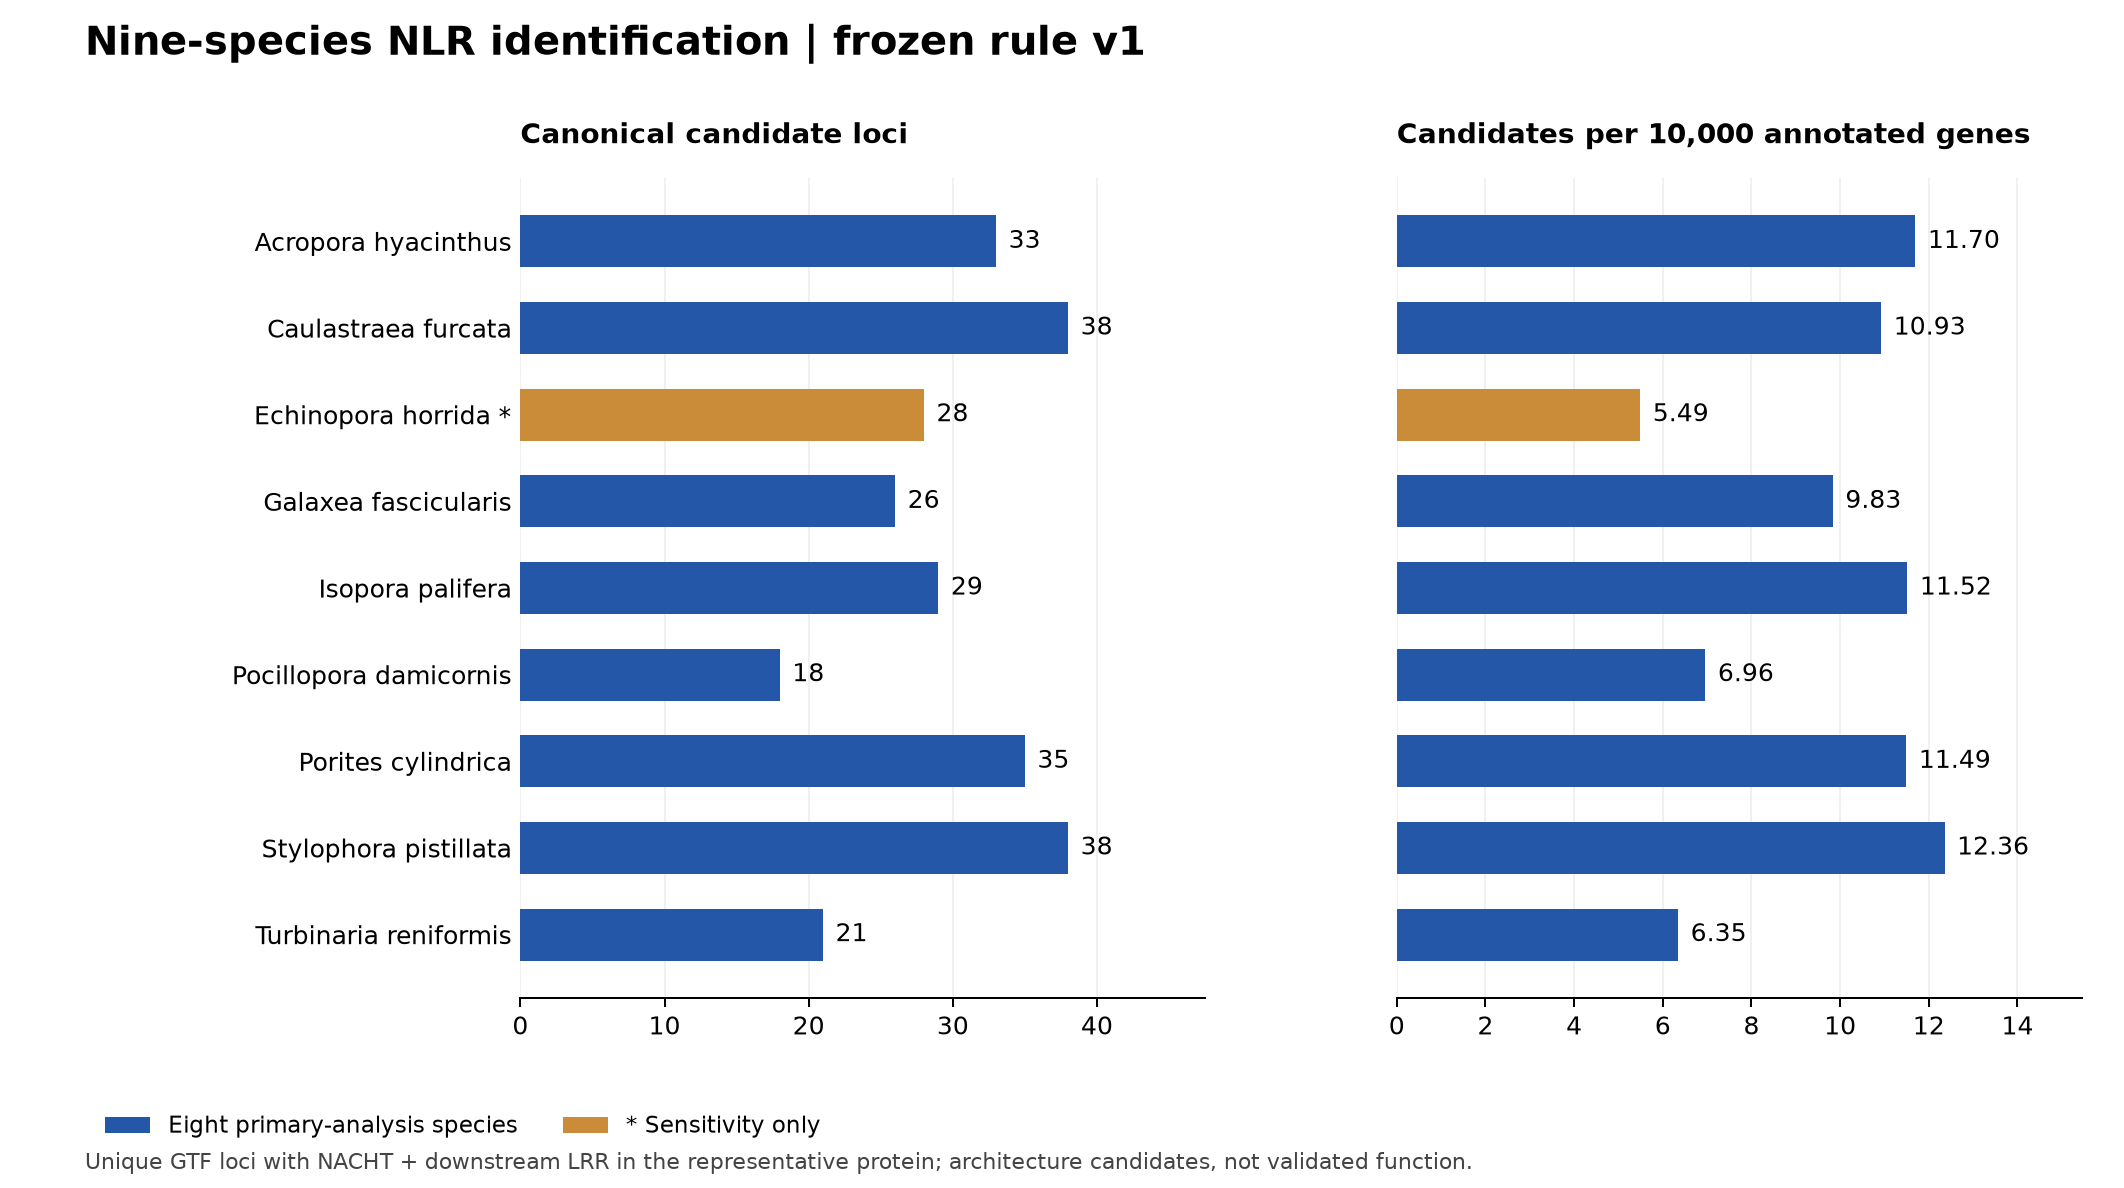

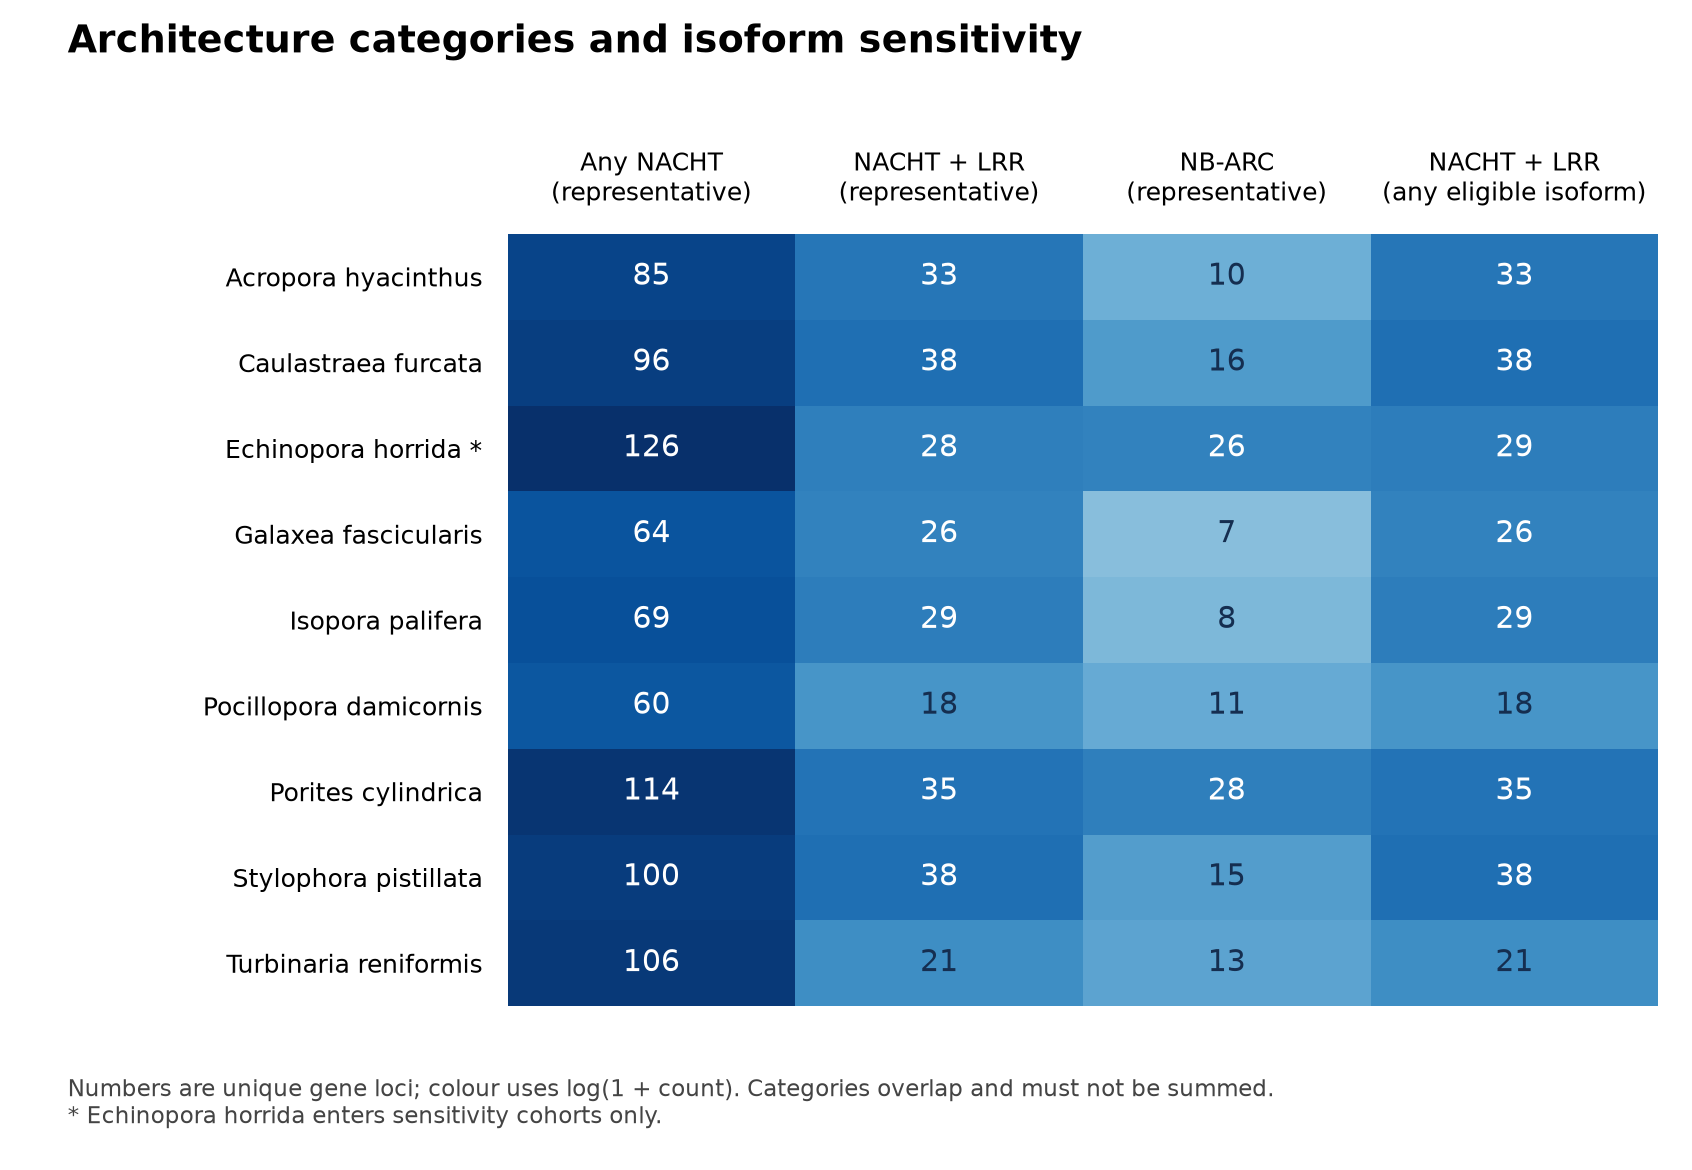

,species,any_isoform_delta,canonical_with_reference_hit,canonical_overlapping_core_models,canonical_multiple_core_flags,canonical_partial_gtf_flags,canonical_ambiguous_residue_flags
0,Acropora hyacinthus,0,33,3,3,0,0
1,Caulastraea furcata,0,38,1,1,0,0
2,Echinopora horrida,1,28,1,1,0,0
3,Galaxea fascicularis,0,26,0,0,0,0
4,Isopora palifera,0,29,1,1,0,0
5,Pocillopora damicornis,0,18,2,2,0,0
6,Porites cylindrica,0,35,12,12,0,0
7,Stylophora pistillata,0,38,2,2,0,0
8,Turbinaria reniformis,0,21,0,0,0,0


In [25]:
display(Image(filename=str(ROOT / "results/figures/nlr_full_counts.png")))
display(Image(filename=str(ROOT / "results/figures/nlr_full_architecture_counts.png")))
display(
    full_exposures[
        [
            "species",
            "any_isoform_delta",
            "canonical_with_reference_hit",
            "canonical_overlapping_core_models",
            "canonical_multiple_core_flags",
            "canonical_partial_gtf_flags",
            "canonical_ambiguous_residue_flags",
        ]
    ]
)

### 5.6 Candidate evidence and exported exposures

Review isoform-dependent loci and overlapping core-model assignments without changing the frozen rule. Gene-level exposure tables and candidate sequences are in `data/processed/nlr_v1/`; full evidence is in `results/nlr_full_v1/`.

In [26]:
isoform_review = pd.read_csv(full_path / "isoform_sensitivity_review.tsv", sep="\t")
display(
    isoform_review[
        [
            "species",
            "gene_id",
            "protein_id",
            "length",
            "is_representative",
            "canonical",
            "nacht",
            "lrr_domains",
            "domains",
        ]
    ]
)
full_candidates = pd.read_csv(
    ROOT / "data/processed/nlr_v1/canonical_candidates.tsv", sep="\t"
)
assert len(full_candidates) == int(full_exposures["canonical"].sum())
assert not full_candidates.duplicated(["genome_id", "gene_id"]).any()
assert full_exposures["unresolved_genes"].eq(0).all()
assert full_exposures["mapping_percent"].eq(100).all()
assert set(full_exposures.loc[full_exposures["primary_eligible"], "species"]) == set(
    PROTOCOL["primary_species"]
)
print(
    "Nine-species identification and audits passed. Association tests follow in Section 7."
)

,species,gene_id,protein_id,length,is_representative,canonical,nacht,lrr_domains,domains
0,Echinopora horrida,g13877,g13877.t1,1261,True,False,True,0,NACHT:302-456
1,Echinopora horrida,g13877,g13877.t2,1207,False,True,True,1,NACHT:302-456;LRR_6:1046-1063


Nine-species identification and audits passed. Association tests follow in Section 7.


<a id="diversity"></a>
## 6 Microbiome diversity and composition

### 6.1 Standardized alpha diversity

For each sample, average Shannon (natural log), observed OTUs and inverse Simpson over 100 subsamples without replacement. Primary depth is 1,000 reads. Use PCG64 with seed 20261117 and recorded SeedSequence streams. Average within recorded colony, then equally across colonies within species; distinct colony labels do not prove biological independence. Monte Carlo ranges describe subsampling variability, not biological confidence intervals.

test_microbiome_metrics.py: passed


prepare_microbiome_metrics.py: passed


summarize_microbiome_metrics.py: passed


,species,n_samples,n_recorded_colonies,shannon_mean,observed_otus_mean,inverse_simpson_mean,single_colony_flag
0,Acropora hyacinthus,2,2,2.2781,54.625,5.1774,False
1,Caulastraea furcata,1,1,3.9375,323.560,13.6329,True
2,Galaxea fascicularis,2,2,4.4061,307.135,22.6034,False
3,Isopora palifera,4,4,2.6449,133.510,5.3751,False
4,Pocillopora damicornis,7,7,1.1217,53.250,2.3528,False
5,Porites cylindrica,2,2,1.0754,77.030,1.4968,False
6,Stylophora pistillata,5,5,1.1485,33.402,3.2096,False
7,Turbinaria reniformis,2,2,5.5238,506.505,119.5855,False


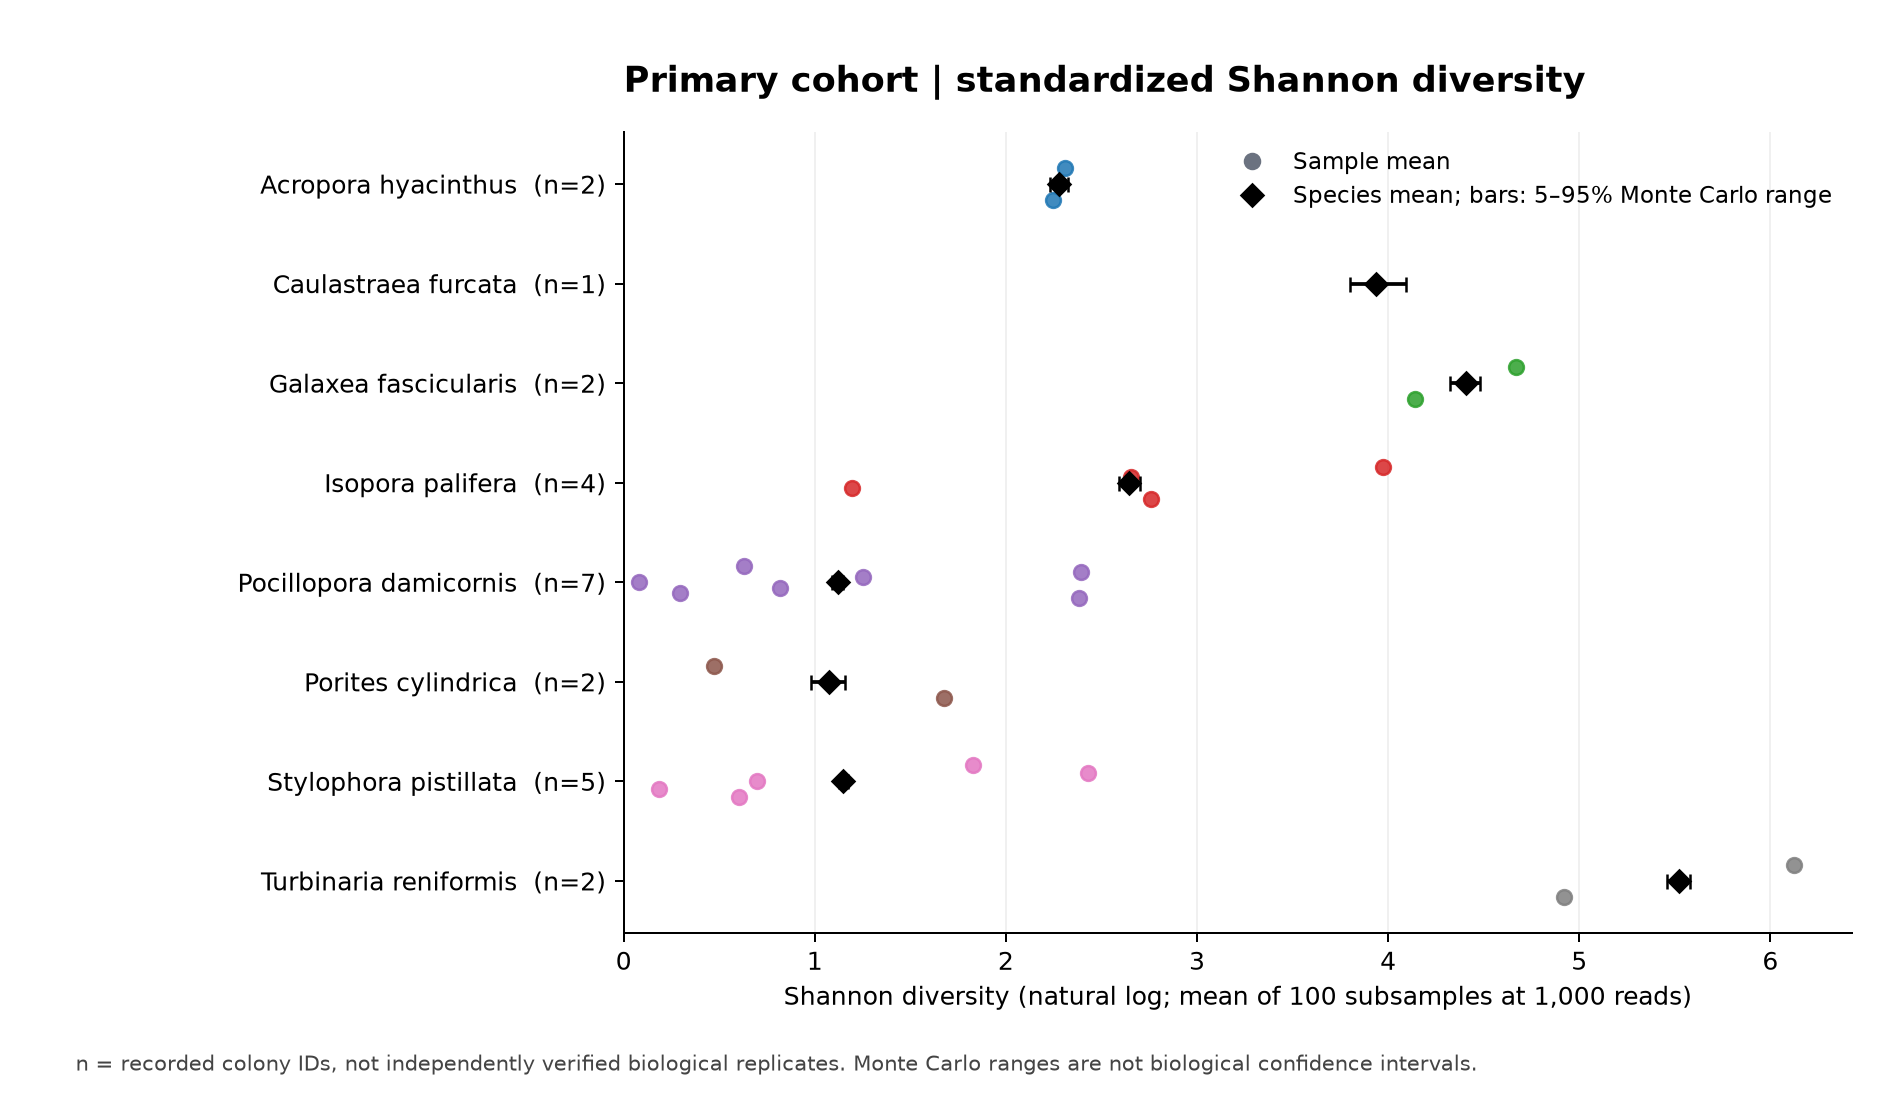

In [27]:
for script in [
    "test_microbiome_metrics.py",
    "prepare_microbiome_metrics.py",
    "summarize_microbiome_metrics.py",
]:
    completed = subprocess.run(
        [sys.executable, str(ROOT / "scripts" / script)],
        cwd=ROOT,
        text=True,
        capture_output=True,
    )
    if completed.returncode:
        print(completed.stdout)
        print(completed.stderr)
        completed.check_returncode()
    print(script + ": passed")
diversity_path = ROOT / "results/microbiome_metrics_v1"
diversity_data = ROOT / "data/processed/microbiome_metrics_v1"
primary_diversity = diversity_data / "primary_strict_mito_agree"
diversity_validation = json.loads((diversity_path / "validation.json").read_text())
diversity_completion = json.loads((diversity_path / "completion.json").read_text())
assert diversity_validation["status"] == diversity_completion["status"] == "complete"
assert not diversity_validation["association_tests_run"]
for relative_path, expected_sha in {
    **diversity_validation["products_sha256"],
    **diversity_completion["products_sha256"],
}.items():
    assert (
        hashlib.sha256((ROOT / relative_path).read_bytes()).hexdigest() == expected_sha
    )
species_alpha = pd.read_csv(primary_diversity / "species_alpha.tsv", sep="\t")
display(
    species_alpha[
        [
            "species",
            "n_samples",
            "n_recorded_colonies",
            "shannon_mean",
            "observed_otus_mean",
            "inverse_simpson_mean",
            "single_colony_flag",
        ]
    ]
)
display(Image(filename=str(ROOT / "results/figures/microbiome_shannon_v1.png")))

### 6.2 Community composition and Bray Curtis ordination

Normalize each unrarefied sample before equal-colony aggregation. PCoA retains the original distances and signed eigenvalues; plotted percentages use positive inertia. Sample ordination is descriptive EDA. Family profiles retain the source taxonomy; top labels are selected by equal-species mean abundance.

,negative_eigenvalues,negative_inertia,positive_inertia,negative_fraction_absolute_inertia,largest_negative_to_largest_positive,numerical_zero_tolerance,axis1_positive_fraction,axis2_positive_fraction,distance_correction,axis_percent_denominator
sample,2,0.0032,10.369,0.0003,0.0012,0.0,0.2694,0.106,none,sum of positive eigenvalues
species,0,-0.0,3.1182,-0.0,0,0.0,0.2586,0.1721,none,sum of positive eigenvalues


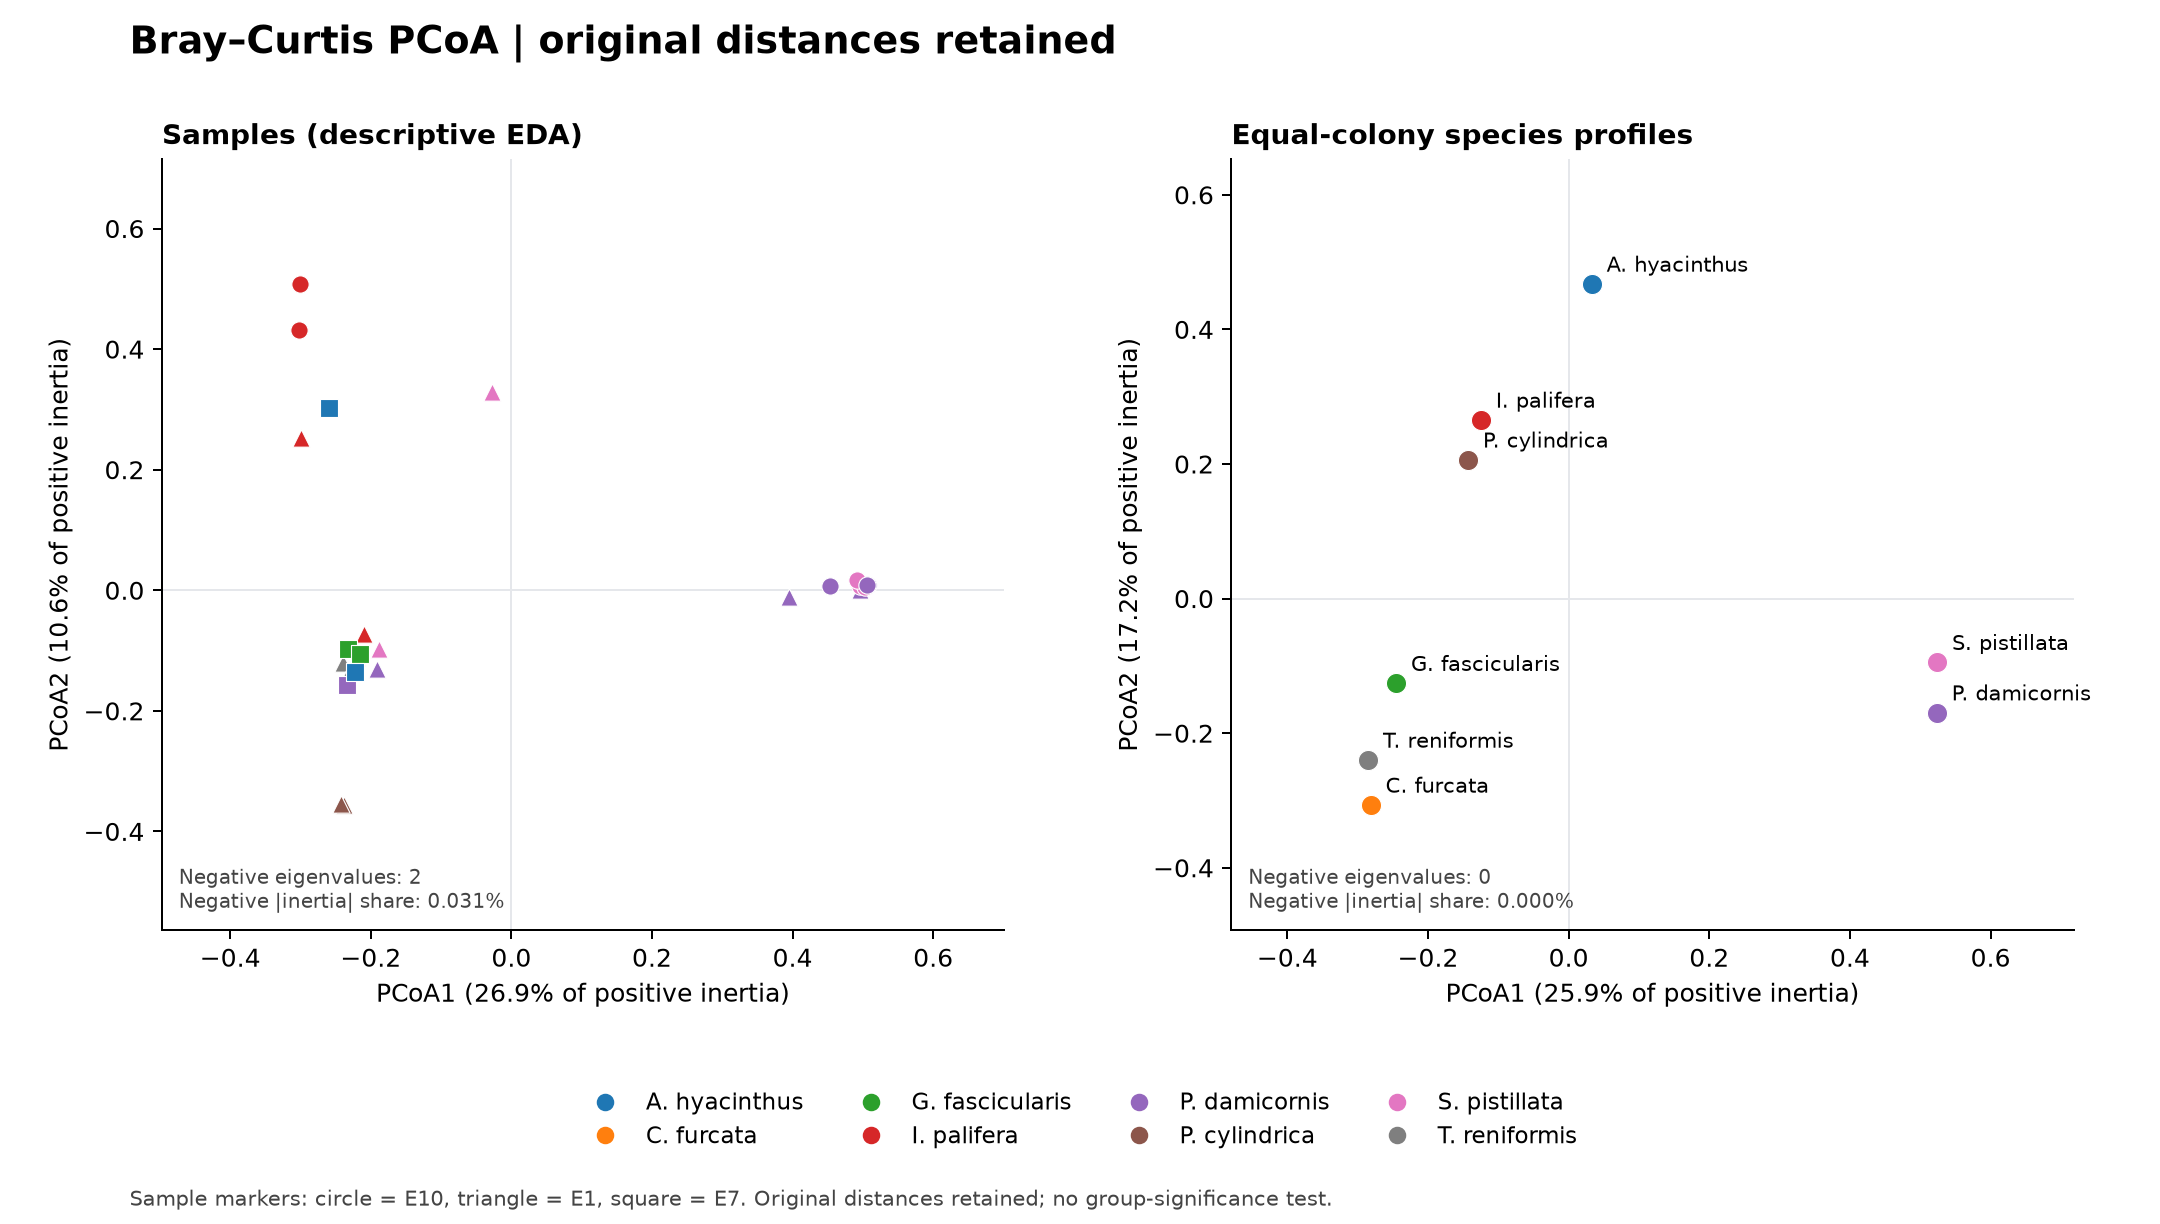

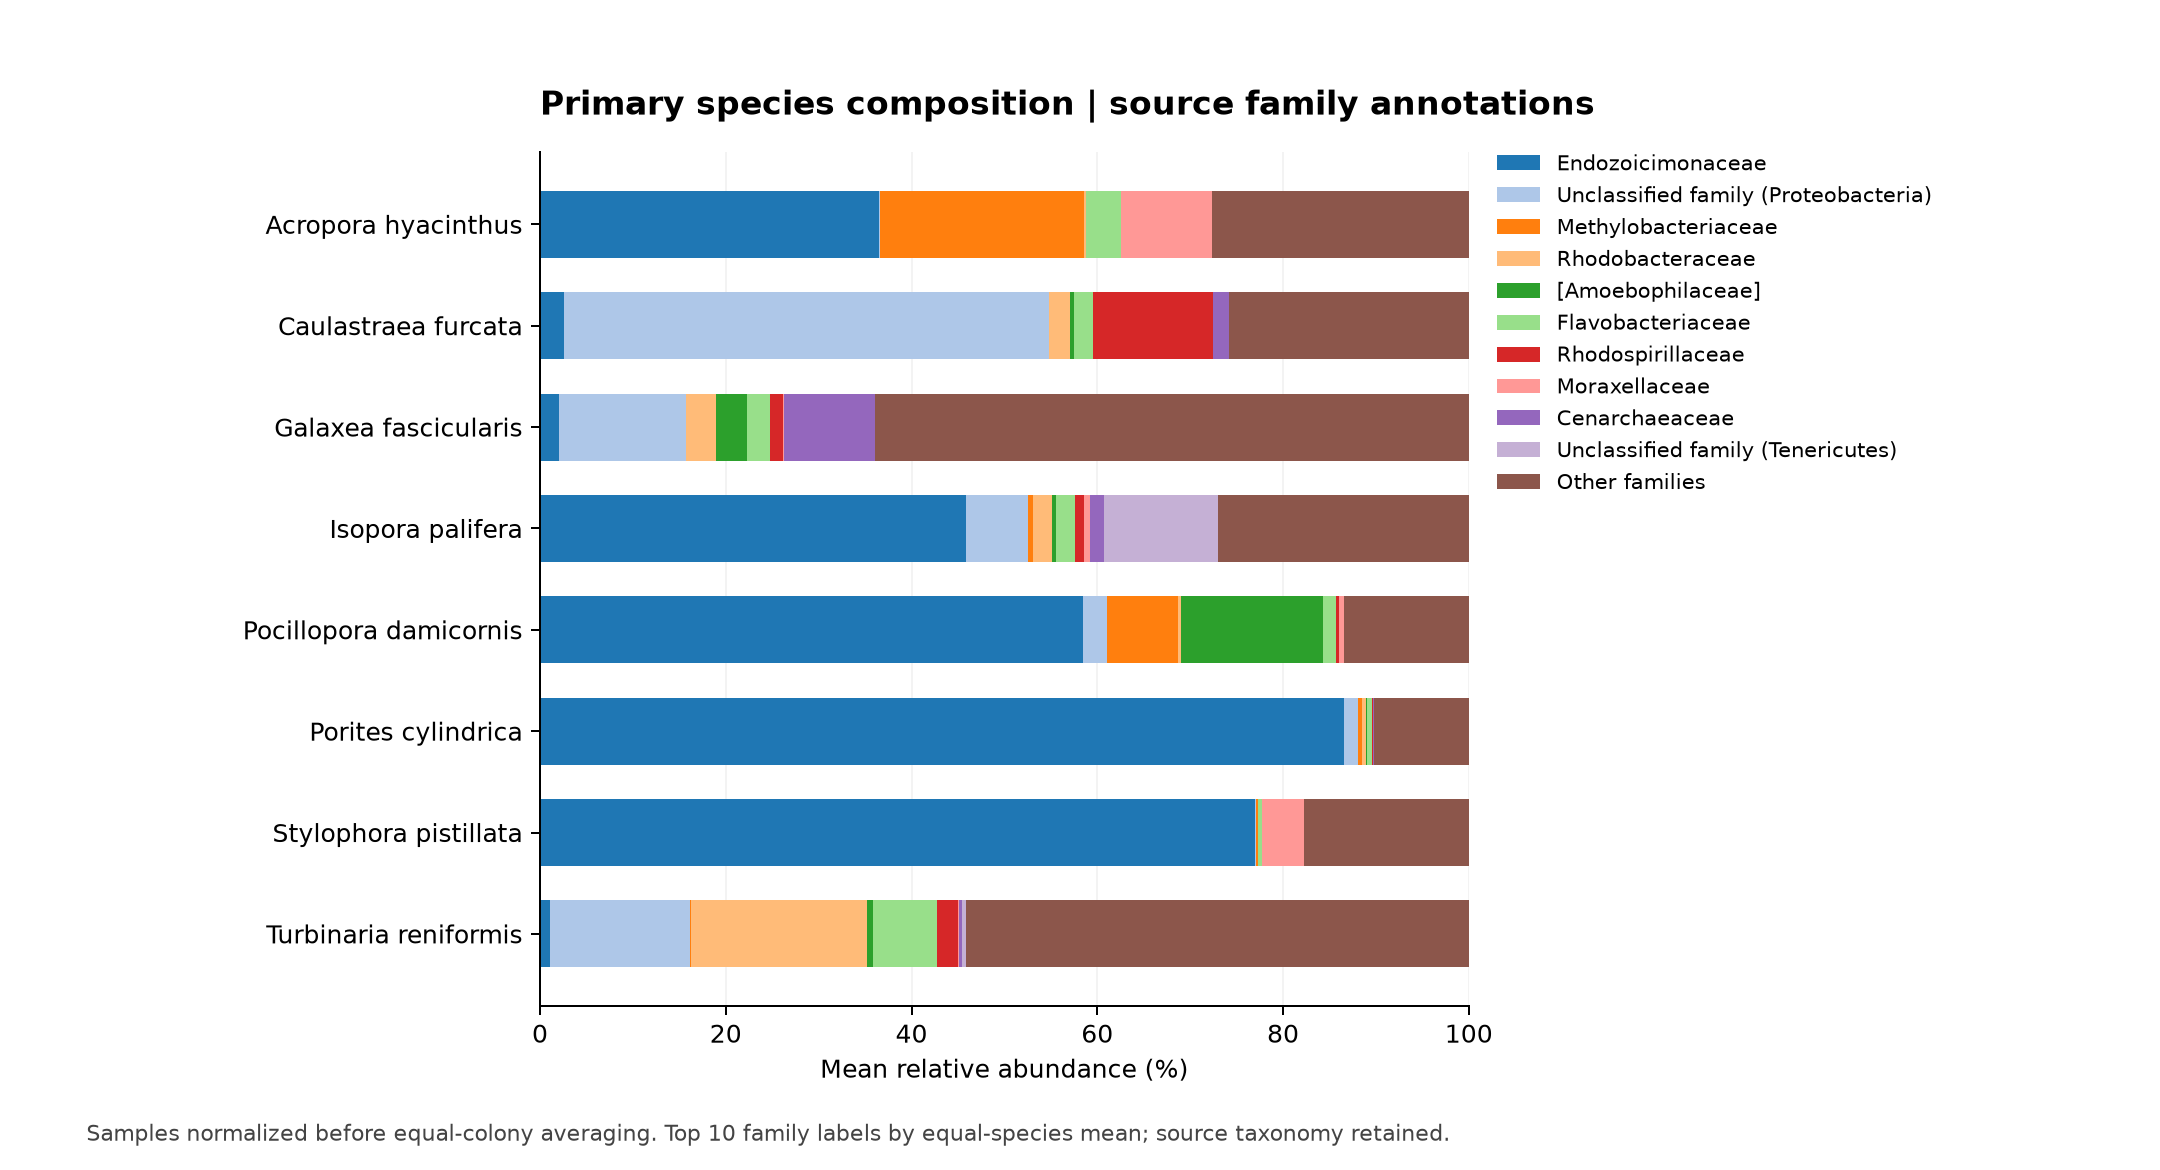

In [28]:
pcoa_diagnostics = json.loads((diversity_path / "pcoa_diagnostics.json").read_text())
display(
    pd.DataFrame(
        {
            level: pcoa_diagnostics["primary_strict_mito_agree/" + level]
            for level in ["sample", "species"]
        }
    ).T
)
display(Image(filename=str(ROOT / "results/figures/microbiome_pcoa_v1.png")))
display(Image(filename=str(ROOT / "results/figures/microbiome_composition_v1.png")))

### 6.3 Depth and eligibility diagnostics

Keep all prespecified scenarios and report lost samples/species. Higher depth changes eligibility; the matched-sample curves separate depth effects from changing cohort membership. The prelisted broad/all-mitotypes cohort changes both health and mitotype criteria. A minimum of three recorded colonies leaves only three species, below the frozen five-species safeguard. The 1,000-read normalization does not imply saturation or complete biological richness.

,scenario,depth,samples,recorded_colonies,species,lost_primary_species,gained_species_vs_primary,fewer_than_5_species
0,primary_strict_mito_agree,1000,25,25,8,,,False
1,sensitivity_strict_all_mitotypes,1000,28,28,8,,,False
2,sensitivity_broad_mito_agree,1000,39,39,9,,Echinopora horrida,False
3,sensitivity_broad_all_mitotypes,1000,54,54,9,,Echinopora horrida,False
4,sensitivity_strict_mito_with_unassigned,1000,26,26,8,,,False
5,primary_depth_2000,2000,23,23,8,,,False
6,primary_depth_5000,5000,19,19,8,,,False
7,primary_depth_10000,10000,16,16,8,,,False
8,primary_min_2_colonies,1000,24,24,7,Caulastraea furcata,,False
9,primary_min_3_colonies,1000,16,16,3,Acropora hyacinthus;Caulastraea furcata;Galaxea fascicularis;Porit...,,True


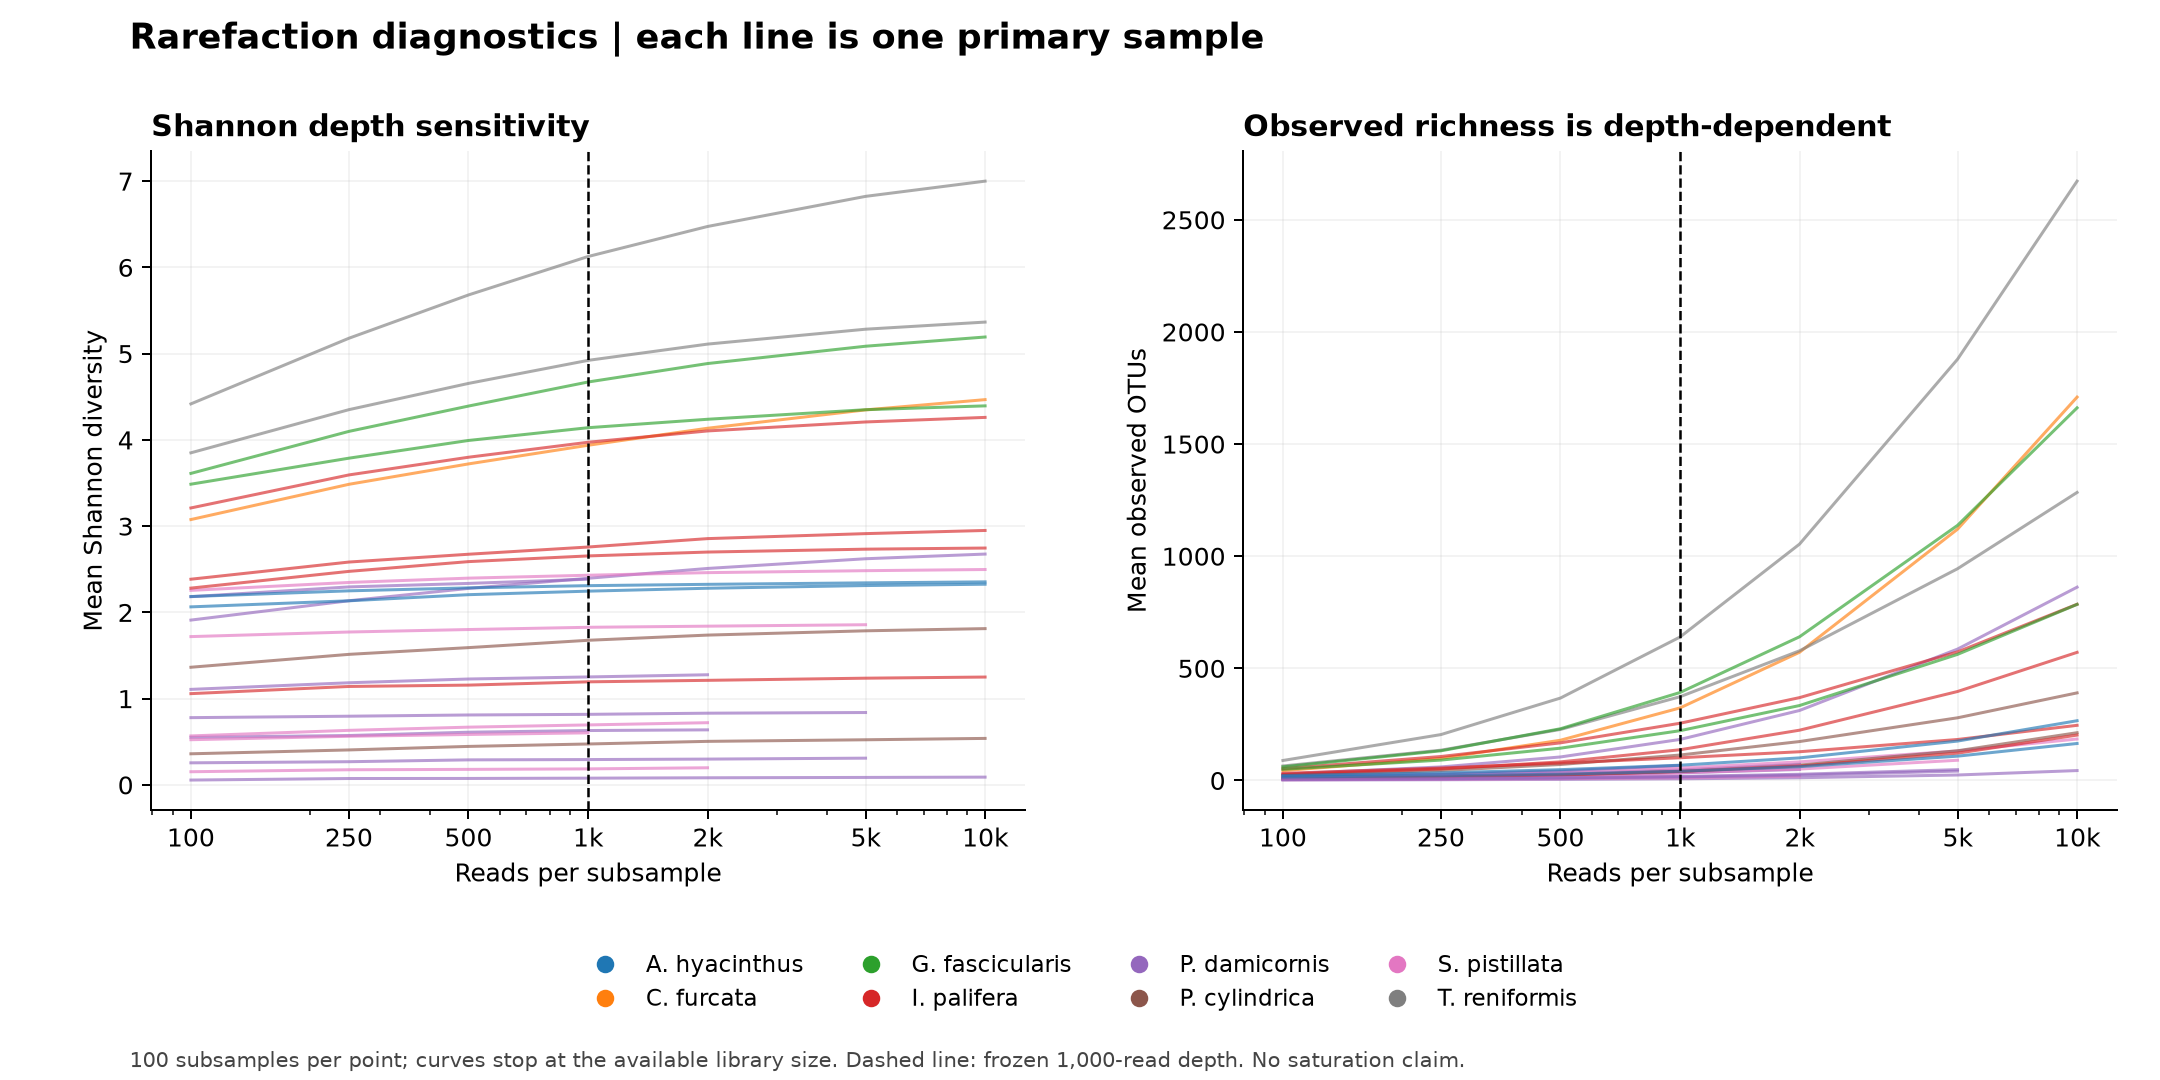

Matched samples at 1,000 and 5,000 reads: 19
Median matched Shannon increase: 0.0784
Median fraction of source-observed OTUs recovered at 1,000 reads: 0.2524
This OTU fraction is not estimated population coverage.


In [29]:
scenario_coverage = pd.read_csv(
    diversity_path / "scenario_coverage.tsv", sep="\t"
).fillna("")
display(
    scenario_coverage[
        [
            "scenario",
            "depth",
            "samples",
            "recorded_colonies",
            "species",
            "lost_primary_species",
            "gained_species_vs_primary",
            "fewer_than_5_species",
        ]
    ]
)
display(Image(filename=str(ROOT / "results/figures/microbiome_rarefaction_v1.png")))
diversity_summary = json.loads((diversity_path / "summary_metrics.json").read_text())
print(
    "Matched samples at 1,000 and 5,000 reads:",
    diversity_summary["shared_samples_at_1000_and_5000"],
)
print(
    "Median matched Shannon increase:",
    round(diversity_summary["matched_sample_shannon_5000_minus_1000_median"], 4),
)
print(
    "Median fraction of source-observed OTUs recovered at 1,000 reads:",
    round(diversity_summary["median_fraction_source_observed_otus_at_1000"], 4),
)
print("This OTU fraction is not estimated population coverage.")

### 6.4 Analysis ready species tables

Validate matching species sets, complete exposures and outcomes, and symmetric zero-diagonal distance matrices. The next section performs the fixed association tests. Preparation output flags describe their own stage, not the completion status of the entire project.

In [30]:
analysis_ready = pd.read_csv(primary_diversity / "analysis_ready_species.tsv", sep="\t")
species_distances = pd.read_csv(
    primary_diversity / "species_bray_curtis.tsv", sep="\t", index_col=0
)
assert set(analysis_ready["species"]) == set(PROTOCOL["primary_species"])
assert set(species_distances.index) == set(analysis_ready["species"])
assert np.allclose(species_distances, species_distances.T)
assert np.allclose(np.diag(species_distances), 0)
assert not analysis_ready[["shannon_mean", "canonical"]].isna().any().any()
assert analysis_ready["n_samples"].sum() == 25
print(
    "Twelve scenarios prepared. Primary species table: 8 rows; Bray-Curtis matrix: 8 x 8."
)
print("Prepared inputs validated. The fixed association tests follow in Section 7.")

Twelve scenarios prepared. Primary species table: 8 rows; Bray-Curtis matrix: 8 x 8.
Prepared inputs validated. The fixed association tests follow in Section 7.


<a id="associations"></a>
## 7 Species level association analysis

### 7.1 Primary Spearman and Mantel tests

A tests candidate count against species-mean Shannon using Spearman correlation. B is a Spearman Mantel test of absolute log1p count differences against Bray–Curtis distances. Permute species labels; for B, move rows and columns together. Use absolute-tail two-sided p values, all permutations for at most eight species and 9,999 random permutations otherwise. Holm correction applies to the two primary endpoints only. Integer-scaled average ranks preserve tied extreme counts exactly.

In [31]:
for script in [
    "test_association_tests.py",
    "run_association_tests.py",
    "audit_association_results.py",
    "summarize_association_tests.py",
]:
    completed = subprocess.run(
        [sys.executable, str(ROOT / "scripts" / script)],
        cwd=ROOT,
        text=True,
        capture_output=True,
    )
    if completed.returncode:
        print(completed.stdout)
        print(completed.stderr)
        completed.check_returncode()
    print(script + ": passed")

test_association_tests.py: passed


run_association_tests.py: passed


audit_association_results.py: passed


summarize_association_tests.py: passed


,endpoint,n_species,n_samples,effect_rho,p_raw,p_holm_primary,permutations,extreme_count
0,A,8,25,-0.2275,0.5859,1,40320,23624
1,B,8,25,-0.0885,0.6176,1,40320,24902


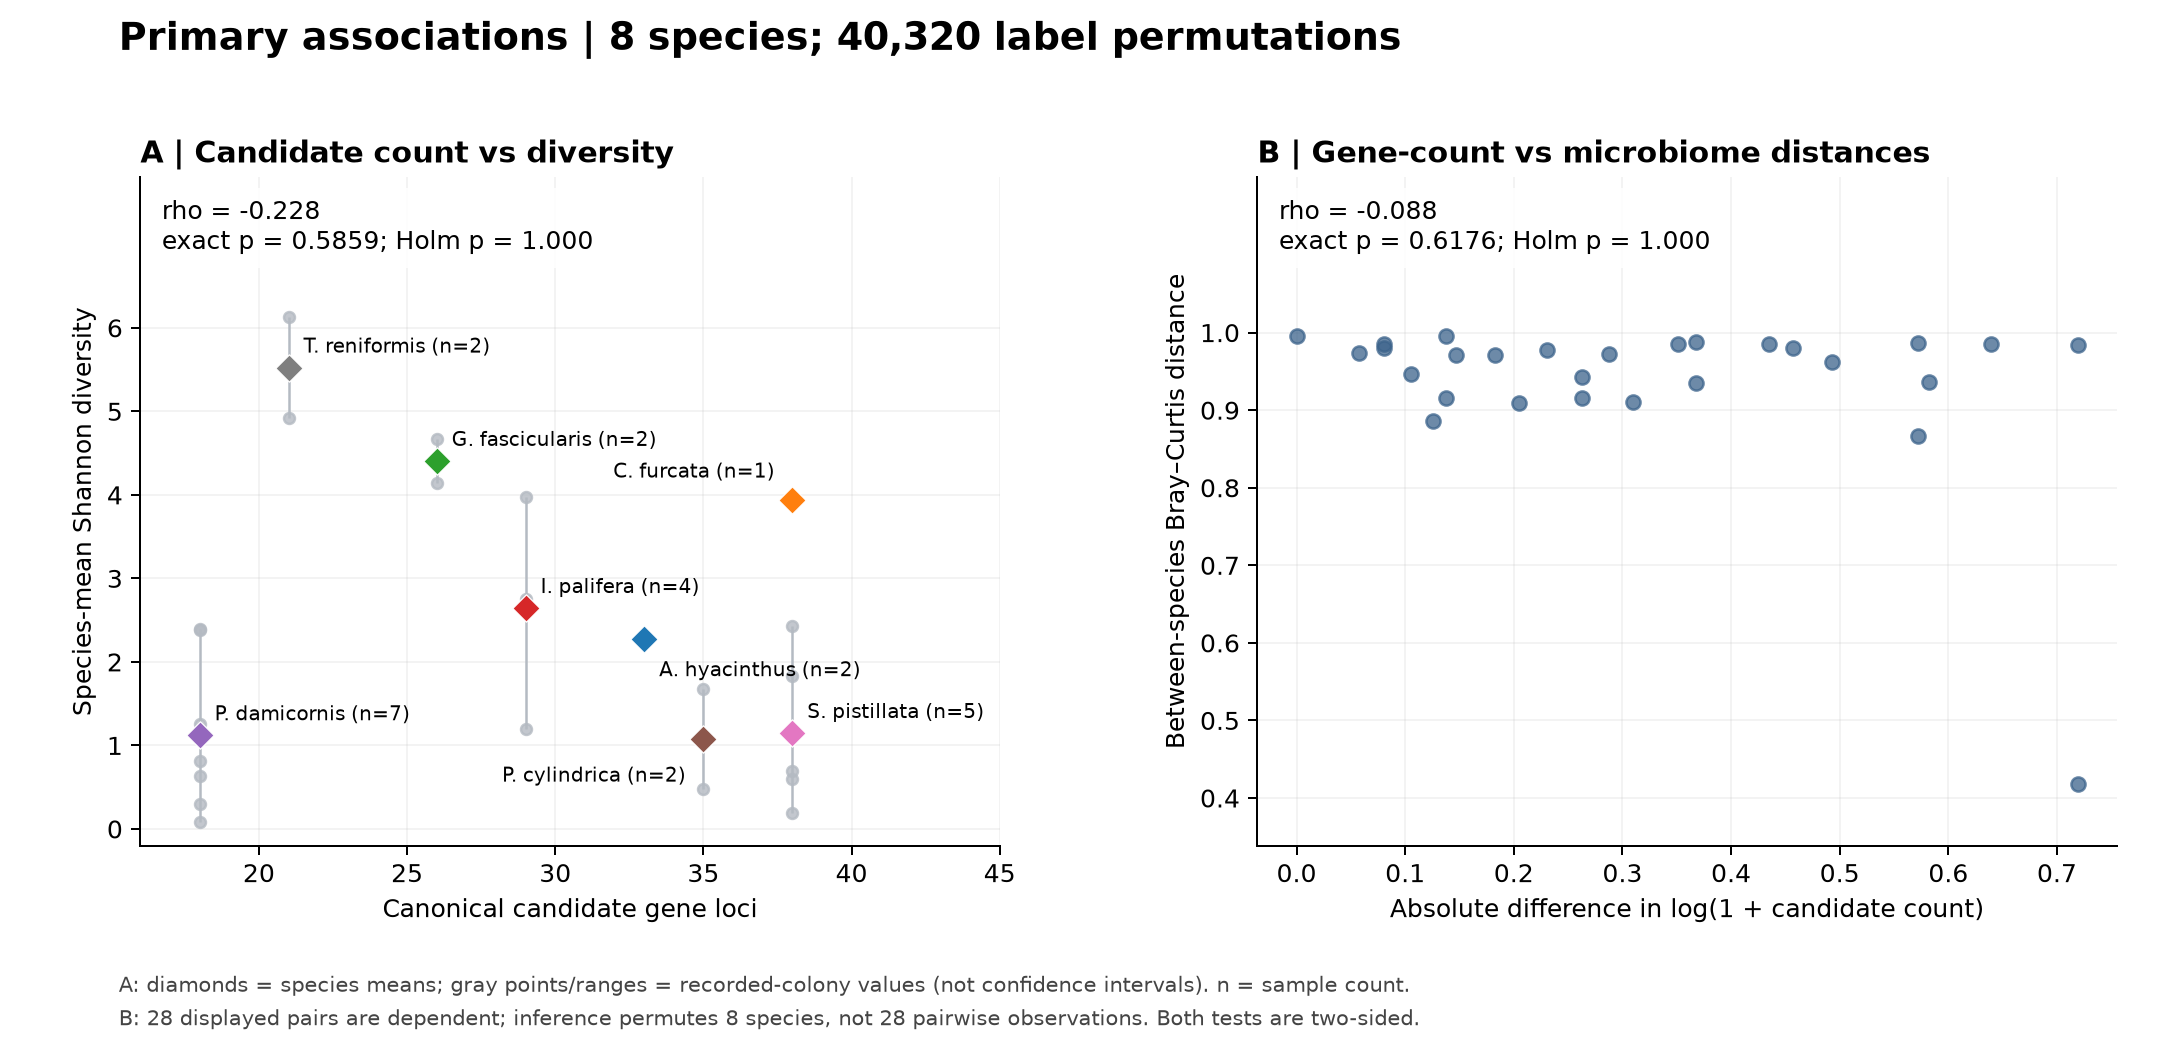

In [32]:
association_path = ROOT / "results/association_v1"
association_validation = json.loads((association_path / "validation.json").read_text())
association_completion = json.loads((association_path / "completion.json").read_text())
assert (
    association_validation["status"] == association_completion["status"] == "complete"
)
for relative_path, expected_sha in {
    **association_validation["products_sha256"],
    **association_completion["products_sha256"],
}.items():
    assert (
        hashlib.sha256((ROOT / relative_path).read_bytes()).hexdigest() == expected_sha
    )
primary_results = pd.read_csv(association_path / "primary_results.tsv", sep="\t")
display(
    primary_results[
        [
            "endpoint",
            "n_species",
            "n_samples",
            "effect_rho",
            "p_raw",
            "p_holm_primary",
            "permutations",
            "extreme_count",
        ]
    ]
)
display(Image(filename=str(ROOT / "results/figures/association_primary_v1.png")))

### 7.2 All prespecified sensitivity results

Show every scheduled scenario. Sensitivity p values are unadjusted and exploratory; they are not independent replications. The minimum-three-colony scenario has only three species, so report descriptive coefficients without p values. The broad/all-mitotypes cohort is the prelisted combined scenario. Unrarefied Shannon changes A only; B is unchanged.

,scenario,endpoint,n_species,effect_rho,p_raw,permutation_method,permutations,status
0,sensitivity_strict_all_mitotypes,A,8,-0.4192,0.3013,exact,40320,tested
1,sensitivity_strict_all_mitotypes,B,8,-0.1819,0.3100,exact,40320,tested
2,sensitivity_broad_mito_agree,A,9,-0.2008,0.6000,monte_carlo,9999,tested
3,sensitivity_broad_mito_agree,B,9,-0.2499,0.1604,monte_carlo,9999,tested
4,sensitivity_broad_all_mitotypes,A,9,-0.2176,0.5689,monte_carlo,9999,tested
5,sensitivity_broad_all_mitotypes,B,9,-0.3411,0.0595,monte_carlo,9999,tested
6,sensitivity_strict_mito_with_unassigned,A,8,-0.3832,0.3448,exact,40320,tested
7,sensitivity_strict_mito_with_unassigned,B,8,-0.1213,0.5019,exact,40320,tested
8,primary_depth_2000,A,8,-0.1078,0.8063,exact,40320,tested
9,primary_depth_2000,B,8,0.0257,0.8903,exact,40320,tested


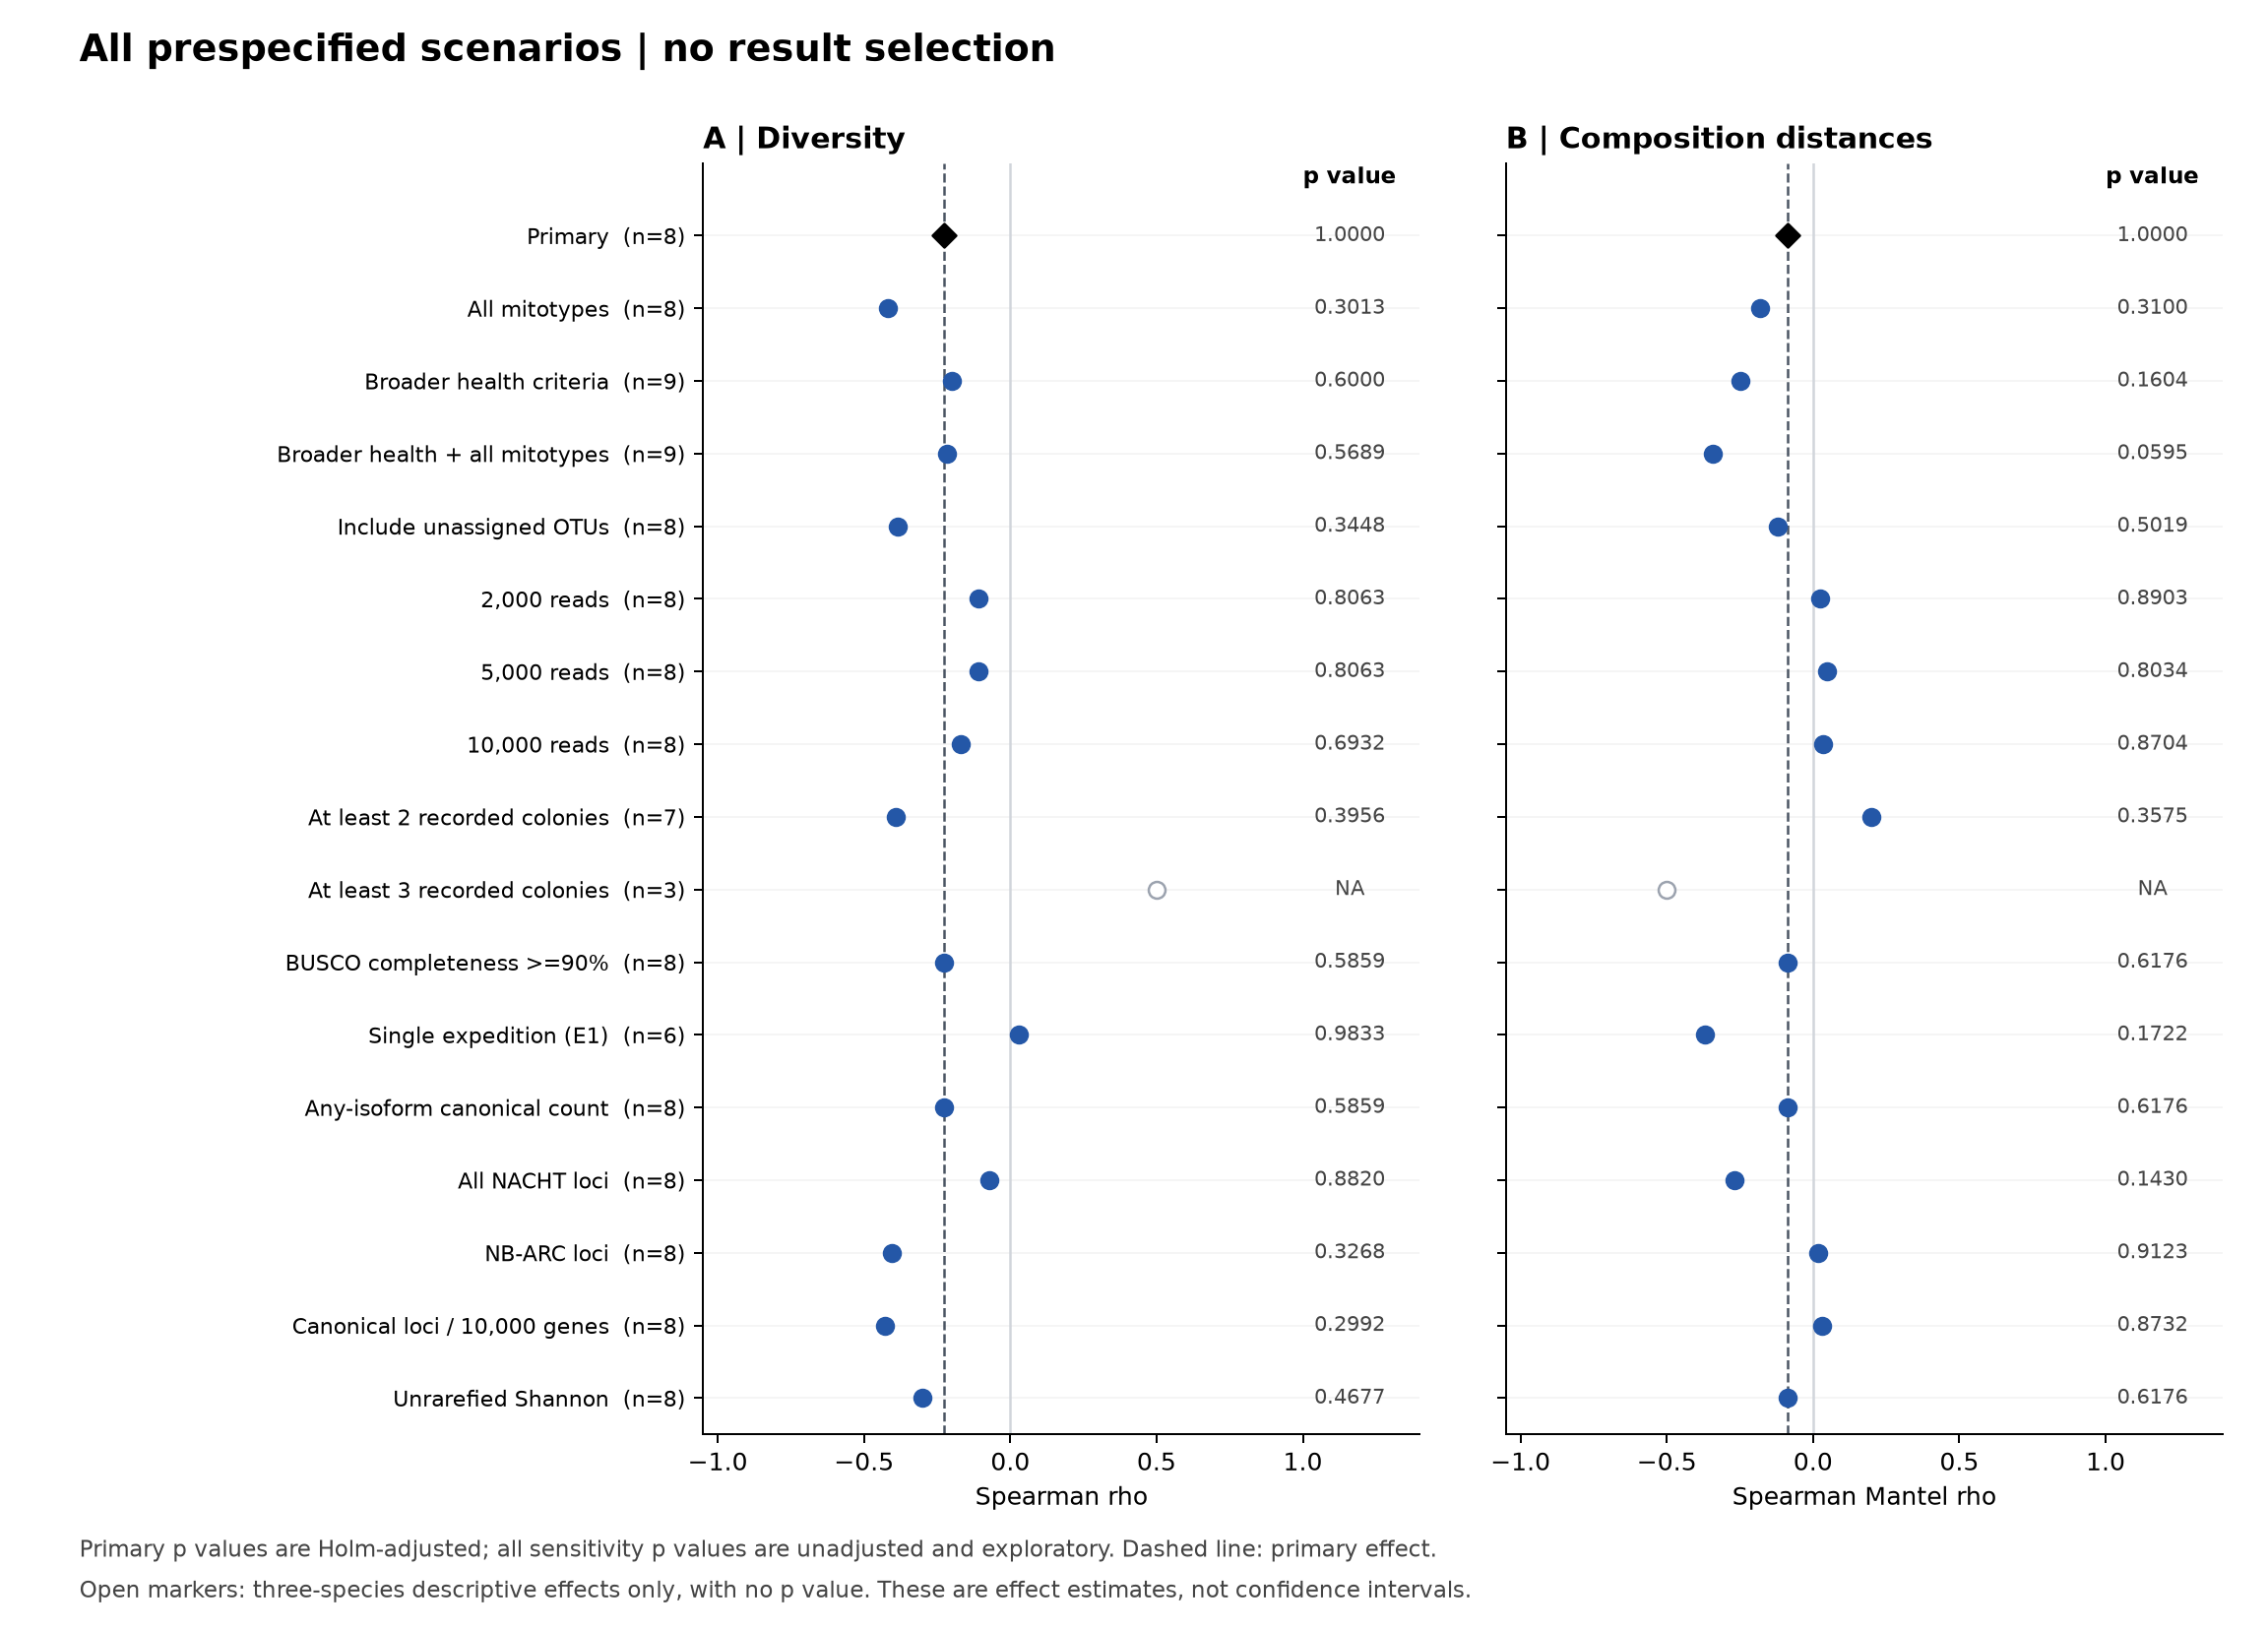

In [33]:
sensitivity_results = pd.read_csv(
    association_path / "sensitivity_results.tsv", sep="\t"
)
display(
    sensitivity_results[
        [
            "scenario",
            "endpoint",
            "n_species",
            "effect_rho",
            "p_raw",
            "permutation_method",
            "permutations",
            "status",
        ]
    ]
)
display(Image(filename=str(ROOT / "results/figures/association_sensitivity_v1.png")))

### 7.3 Species influence and geographic coverage

Leave-one-species-out ranges are effect diagnostics, not confidence intervals. Record site/expedition coverage. The supplied host tree is not an accepted species-level PGLS input; neither the lambda=1 model nor its lambda=0 contrast is run. Species exchangeability may be violated by ancestry and geography. The single-expedition sensitivity does not constitute geographic adjustment.

,omitted_species,endpoint,n_species,effect_rho
0,Acropora hyacinthus,A,7,-0.1802
1,Acropora hyacinthus,B,7,-0.1034
2,Caulastraea furcata,A,7,-0.3929
3,Caulastraea furcata,B,7,0.2000
4,Galaxea fascicularis,A,7,-0.0541
5,Galaxea fascicularis,B,7,-0.2088
6,Isopora palifera,A,7,-0.1802
7,Isopora palifera,B,7,-0.2166
8,Pocillopora damicornis,A,7,-0.6667
9,Pocillopora damicornis,B,7,-0.1743


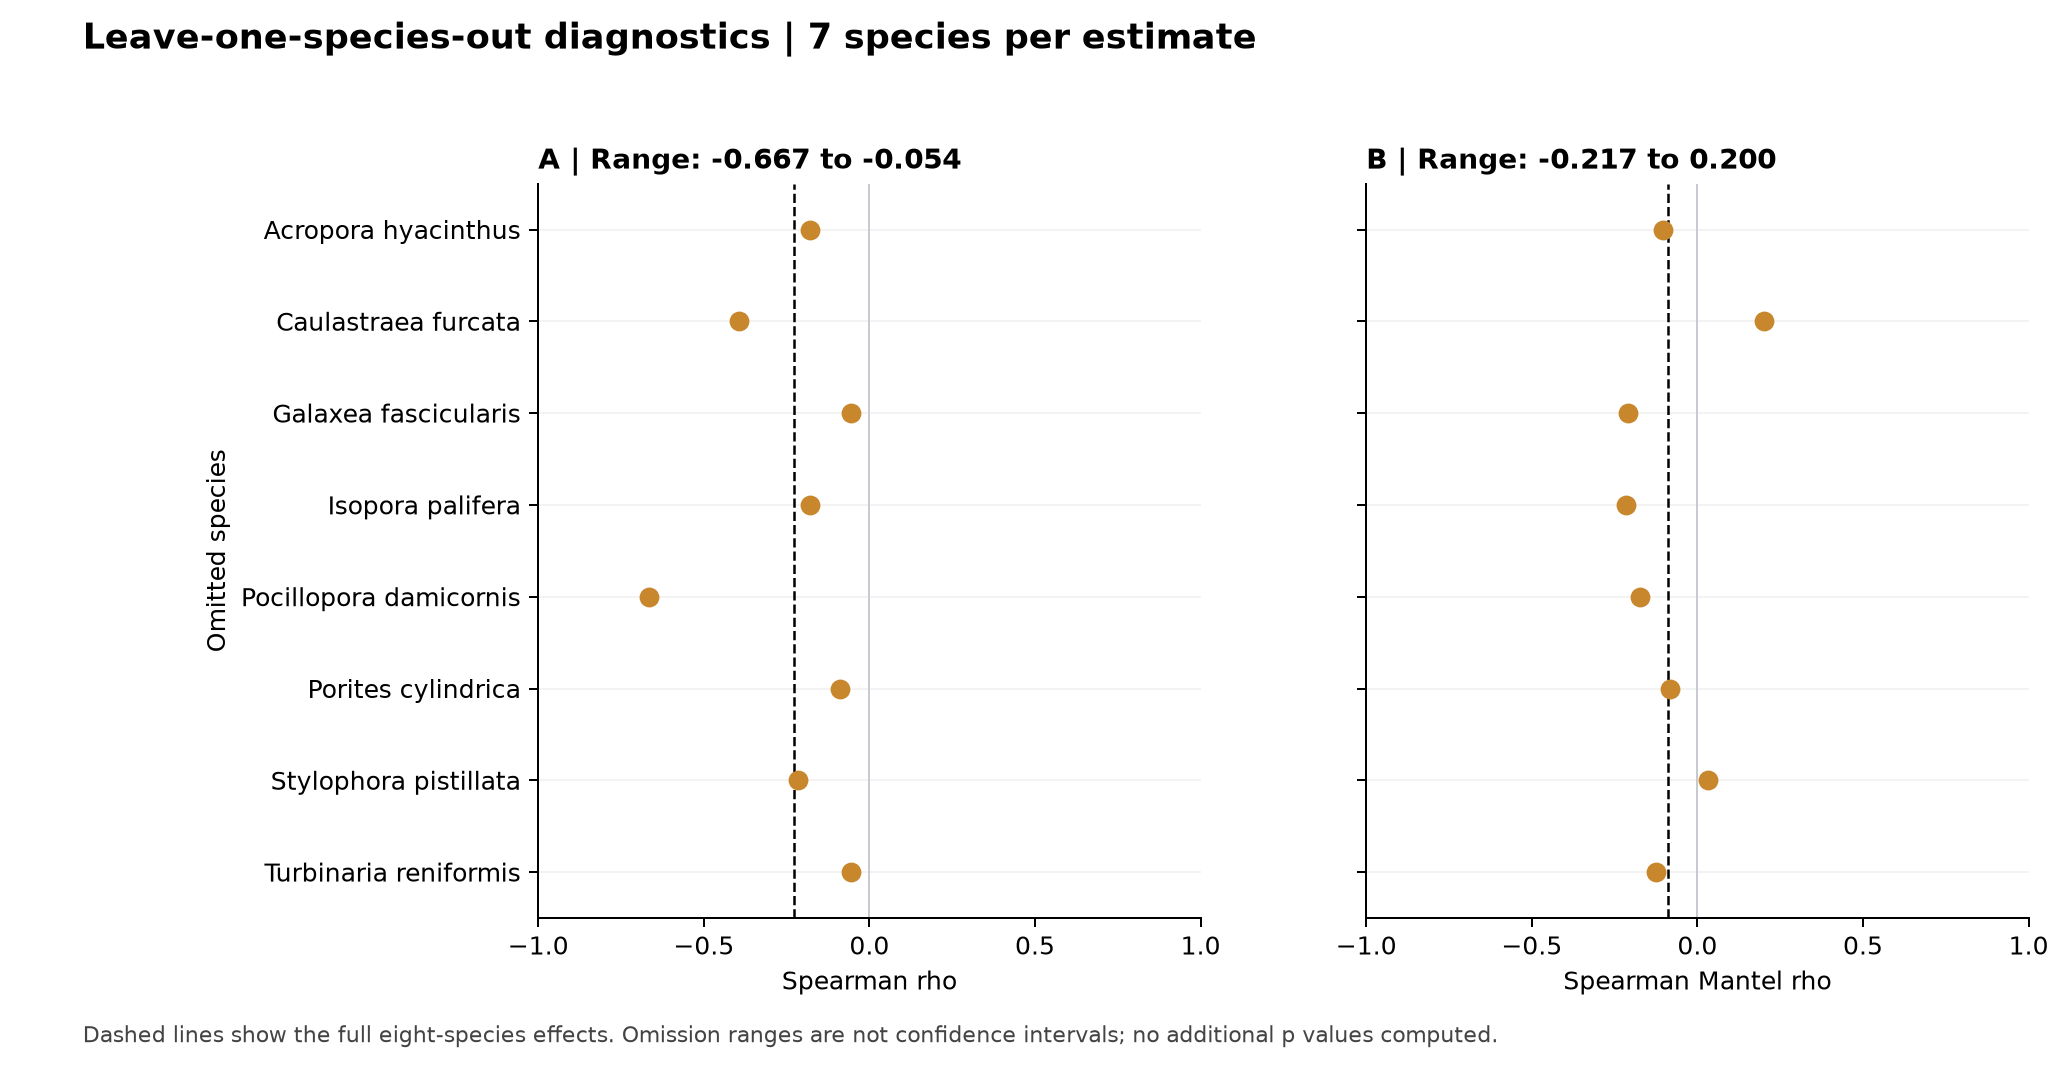

,canonical_species,E10_Lord_Howe_2015,E1_Lizard_Island_2014,E7_Ningaloo_2015
0,Acropora hyacinthus,0,0,2
1,Caulastraea furcata,0,1,0
2,Galaxea fascicularis,0,0,2
3,Isopora palifera,2,2,0
4,Pocillopora damicornis,3,3,1
5,Porites cylindrica,0,2,0
6,Stylophora pistillata,3,2,0
7,Turbinaria reniformis,0,2,0


{
  "status": "not_performed",
  "reason": "Frozen source tree not accepted as species-level PGLS input; no validated replacement present.",
  "frozen_tree": "data/raw/phylogeny/pollock2018/host_tree_from_step_11.newick",
  "mapping_sha256": "95e2ccab667949811f26231bbb207c55a7fe9da9295338eaaa43f642c3aa10cd",
  "ancestry_adjusted": false,
  "lambda_1_run": false,
  "lambda_0_contrast_run": false,
  "geographic_adjustment": "none; preplanned single-expedition sensitivity reported separately"
}


In [34]:
leave_one_species_out = pd.read_csv(
    association_path / "leave_one_species_out.tsv", sep="\t"
)
display(
    leave_one_species_out[["omitted_species", "endpoint", "n_species", "effect_rho"]]
)
display(Image(filename=str(ROOT / "results/figures/association_leave_one_out_v1.png")))
display(
    pd.read_csv(association_path / "species_expedition_sample_counts.tsv", sep="\t")
)
phylogeny_status = json.loads((association_path / "phylogeny_status.json").read_text())
# Display a project-relative tree path; preserve the saved provenance record.
phylogeny_display = dict(phylogeny_status)
phylogeny_display["frozen_tree"] = "data/raw/phylogeny/pollock2018/host_tree_from_step_11.newick"
print(json.dumps(phylogeny_display, indent=2))

<a id="conclusion"></a>
## 8 Interpretation and final verification

Neither primary endpoint supports the predicted positive association after Holm correction. This does not establish absence of an immune effect or absence of host-species differences. Eight species, uneven sampling, depth sensitivity, uncertain colony independence and predicted gene architectures limit inference. PGLS and PERMANOVA were not performed. Independent exact-permutation audits verify the primary calculations.

In [35]:
association_audit = json.loads(
    (association_path / "independent_audit.json").read_text()
)
assert association_audit["status"] == "passed"
assert primary_results["permutations"].eq(40320).all()
assert primary_results["n_species"].eq(8).all()
assert (
    sensitivity_results.loc[sensitivity_results["status"] != "tested", "p_raw"]
    .isna()
    .all()
)
assert phylogeny_status["status"] == "not_performed"
print(association_completion["primary_conclusion"])
print("Independent primary tests and all saved null-distribution p values verified.")
print("Full report: reports/association_v1_report.txt")

Neither primary endpoint reaches the frozen 0.05 threshold after Holm correction.
Independent primary tests and all saved null-distribution p values verified.
Full report: reports/association_v1_report.txt


In [36]:
# Final compact results for reading and presentation.
display(
    primary_results[
        ["endpoint", "n_species", "effect_rho", "p_raw", "p_holm_primary"]
    ].rename(
        columns={
            "endpoint": "Test",
            "n_species": "Species",
            "effect_rho": "rho",
            "p_raw": "Raw p",
            "p_holm_primary": "Holm p",
        }
    )
)
eligible = sensitivity_results.loc[sensitivity_results["status"].eq("tested")]
print(
    f"Eligible sensitivity endpoint tests: {len(eligible)}; raw p < 0.05: {int(eligible['p_raw'].lt(0.05).sum())}."
)
print("Sensitivity tests are exploratory and not independent replications.")
print("Project guide: README.md; Python dependencies: requirement.txt.")

,Test,Species,rho,Raw p,Holm p
0,A,8,-0.2275,0.5859,1
1,B,8,-0.0885,0.6176,1


Eligible sensitivity endpoint tests: 30; raw p < 0.05: 0.
Sensitivity tests are exploratory and not independent replications.
Project guide: README.md; Python dependencies: requirement.txt.


### Output locations

- `data/processed/`: cleaned cohorts, gene counts and analysis-ready metrics.
- `results/figures/`: QC, candidate identification, diversity and association figures.
- `results/association_v1/`: all endpoint tests, permutation nulls and independent audit.
- `requirement.txt`: Python dependencies, complete environment setup commands and the embedded conda package specification.

For rerun commands, data provenance and limitations, see the project [README](README.md).